<h1 style="text-align: center;">Bank Marketing Campaign</h1>
<h3 style="text-align: center;">Team Beta</h3>

---

## **Section 0. Setup**

### *0.1 Import Library*

In [4]:
# import library dasar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# preprocessing & pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, KBinsDiscretizer, StandardScaler, RobustScaler
from sklearn.feature_selection import SelectFpr

# model
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier

# evaluasi
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay, average_precision_score

# interpretasi & deployment
import shap
import joblib
import sklearn, xgboost, lightgbm

# Tunning
import optuna


### *0.2 Global Configuration*

In [5]:
RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## **Section 1. Business Understanding**

### *1.1 Context*
- Latar Belakang: Kampanye telemarketing adalah salah satu saluran utama bagi perbankan untuk menawarkan produk deposito berjangka kepada nasabah. Namun, pendekatan konvensional yang menelepon nasabah secara acak (blanket marketing) sering kali tidak efisien, membuang waktu operasional agen, menyebabkan kelelahan kontak (contact fatigue), dan menghasilkan rasio konversi (conversion rate) yang sangat rendah.

- Stakeholder Utama: Tim Manajemen Pemasaran (Marketing Management) dan Tim Operasional Telemarketing (Telemarketing Sales Team).

- Urgensi Masalah: Dengan adanya keterbatasan kuota operasional harian (misalnya keterbatasan jumlah agen atau kapasitas panggilan telepon terbatas, seperti skenario maksimal 500 panggilan dari total ribuan basis data prospek), bank membutuhkan sistem penyaringan cerdas agar setiap panggilan telepon berfokus pada nasabah yang memiliki probabilitas konversi tertinggi.

### *1.2 Problem Statements*
- Bagaimana cara mengidentifikasi calon nasabah yang memiliki potensi tinggi untuk membuka rekening deposito berdasarkan data demografi dan riwayat interaksi kampanye sebelumnya?

- Bagaimana mengatasi rendahnya efisiensi operasional akibat kampanye telemarketing yang dilakukan secara acak tanpa penargetan berbasis data?

- Bagaimana mengoptimalkan kuota panggilan telepon yang terbatas agar dapat menjaring jumlah nasabah sukses deposit secara maksimal sekaligus menekan biaya operasional (cost-per-acquisition)?

### *1.3 Goals*
- Mengembangkan model Machine Learning prediktif yang akurat untuk memberikan skor probabilitas konversi deposit bagi setiap nasabah baru (unseen prospects).

- Menerapkan strategi Top-N Lead Prioritization (pengurutan prioritas kontak berdasarkan skor probabilitas) untuk memandu operasional harian tim telemarketing.

- Membuktikan peningkatan efisiensi finansial dan perolehan Net Profit melalui simulasi bisnis berbasis data uji aktual (cost-benefit analysis).

### *1.4 Analytical Approach*
- Pendekatan yang digunakan adalah Supervised Machine Learning dengan spesifikasi tugas Klasifikasi Biner (Binary Classification).

- Model bertugas mempelajari pola dari data historis nasabah (demografi, riwayat pinjaman/KPR, kanal komunikasi, dan hasil kampanye masa lalu) untuk memprediksi apakah seorang nasabah akan merespons positif (Label 1 = Ya/Deposit) atau negatif (Label 0 = Tidak).

- Algoritma utama yang dipilih dan dioptimalkan adalah Gradient Boosting Classifier, yang didukung oleh tahapan preprocessing terstruktur (One-Hot Encoding, imputasi, dan penskalaan numerik) di dalam objek Pipeline Scikit-Learn.

### *1.5 Metric Evaluation (Business Metric, Machine Learning Evaluation Metric)*
Machine Learning Evaluation Metric:

- PR-AUC (Precision-Recall Area Under Curve): Digunakan sebagai metrik utama karena dataset target yang bersifat imbalanced (jumlah nasabah yang menolak jauh lebih banyak dibanding yang menerima).

- Precision & Recall: Mengukur keandalan prediksi positif (presisi di atas 60%–80% untuk skor tinggi) dan kemampuan model menjaring seluruh potensi nasabah.

Business Metric:

- Cost Efficiency & Net Profit: Mengukur penghematan biaya operasional telemarketing (pengurangan panggilan sia-sia) dan peningkatan keuntungan bersih bank dari akumulasi sukses deposit dikurangi biaya panggilan.

### *1.6 Success Criteria*
- Model Performance: Model dianggap layak secara teknis jika menghasilkan kurva kalibrasi yang andal dan mampu mempertahankan tingkat Presisi $\ge 80\%$ pada kelompok skor probabilitas tertinggi (> 0.6).

- Operational & Business Impact: Berdasarkan simulasi kuota terbatas (misalnya pembatasan 500 panggilan), model harus mampu membuktikan peningkatan perolehan nasabah sukses deposit yang jauh lebih tinggi dan memberikan peningkatan Net Profit yang signifikan dibandingkan metode pemilihan acak (random baseline).

## **Section 2. Data Understanding**

### *2.1 General Information*

In [6]:
# Import Dataset
df = pd.read_csv('data_bank_marketing_campaign.csv')

# Info Dataset
print('Ukuran data:', df.shape)
print(df.info())

Ukuran data: (7813, 11)
<class 'pandas.DataFrame'>
RangeIndex: 7813 entries, 0 to 7812
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   age       7813 non-null   int64
 1   job       7813 non-null   str  
 2   balance   7813 non-null   int64
 3   housing   7813 non-null   str  
 4   loan      7813 non-null   str  
 5   contact   7813 non-null   str  
 6   month     7813 non-null   str  
 7   campaign  7813 non-null   int64
 8   pdays     7813 non-null   int64
 9   poutcome  7813 non-null   str  
 10  deposit   7813 non-null   str  
dtypes: int64(4), str(7)
memory usage: 932.4 KB
None


In [7]:
print('5 Data Teratas pada Dataset:')
df.head()

5 Data Teratas pada Dataset:


,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome,deposit
0,55,admin.,1662,no,no,cellular,jun,2,-1,unknown,yes
1,39,self-employed,-3058,yes,yes,cellular,apr,3,-1,unknown,yes
2,51,admin.,3025,no,no,cellular,may,1,352,other,yes
3,38,services,-87,yes,no,cellular,may,1,-1,unknown,no
4,36,housemaid,205,yes,no,telephone,nov,4,-1,unknown,no


**Insight:**
- Dataset berisi **7.813 baris** dan **11 kolom** yang terdiri dari 4 kolom numerik (age, balance, campaign, pdays) dan 7 kolom kategorikal (job, housing, loan, contact, month, poutcome,deposit).
- Tidak terdapat nilai kosong (NaN) dan tipe data sudah sesuai.

### *2.2 Feature Information*

| Feature | Description | Impact to Business |
|---------|-------------|--------------------|
| `age` | Usia nasabah (tahun) | Kebutuhan dan kemampuan menabung berbeda di tiap usia; nasabah berumur muda (pelajar) dan lansia (pensiunan) bisa memounyayi pola yang berbeda dari usia produktif |
| `job` | Jenis pekerjaan nasabah | Mencerminkan stabilitas ekonomi dan besaran penghasilan yang memengaruhi kemampuan menyisihkan dana untuk deposito |
| `balance` | Saldo rekening nasabah | Saldo lebih besar berarti ada dana menganggur yang bisa dipindahkan ke deposito, saldo mines memungkinkan jika nasabah sedang mempunyai pinjaman / kewajiban membayar cicilan |
| `housing` | Apakah nasabah memiliki cicilan rumah (KPR) (`yes`/`no`) | Cicilan rumah mengurangi dana yang bisa disimpan; nasabah tanpa KPR berpotensi lebih mudah deposit |
| `loan` | Apakah nasabah memiliki pinjaman pribadi (`yes`/`no`) | Sama seperti KPR, kewajiban pinjaman menekan kemampuan menabung |
| `contact` | Jenis kontak yang dipakai (`cellular`, `telephone`, `unknown`) | Menentukan saluran campaign yang paling efektif |
| `month` | Bulan kontak terakhir | Menunjukkan pengaruh waktu/musim terhadap keberhasilan campaign sehingga berguna untuk menjadwalkan campaign |
| `campaign` | Jumlah kontak ke nasabah selama campaign yang sedang berjalan | Terlalu sering dihubungi bisa membuat nasabah jenuh dan bisa menjadi acuan batas frekuensi kontak nasabah |
| `pdays` | Jumlah hari sejak nasabah dihubungi pada campaign sebelumnya (`-1` = belum pernah dihubungi) | Nasabah yang pernah dihubungi punya riwayat interaksi dengan bank |
| `poutcome` | Hasil campaign sebelumnya (`success`, `failure`, `other`, `unknown`) | Nasabah yang pernah berhasil di campaign sebelumnya kemungkinan besar berminat lagi |
| `deposit` | **Target**: apakah nasabah membuka deposito (`yes`/`no`) | Hasil yang ingin diprediksi untuk menentukan prioritas kontak |

### *2.3 Statistics Summary*

In [8]:
display(df.describe())
display(df.describe(include=['object', 'string']))

,age,balance,campaign,pdays
count,7813.000000,7813.000000,7813.000000,7813.000000
mean,41.257264,1512.448611,2.519775,51.408550
std,11.919710,3089.291831,2.727001,108.072739
min,18.000000,-6847.000000,1.000000,-1.000000
25%,32.000000,127.000000,1.000000,-1.000000
50%,39.000000,549.000000,2.000000,-1.000000
75%,49.000000,1684.000000,3.000000,40.000000
max,95.000000,66653.000000,63.000000,854.000000


,job,housing,loan,contact,month,poutcome,deposit
count,7813,7813,7813,7813,7813,7813,7813
unique,12,2,2,3,12,4,2
top,management,no,no,cellular,may,unknown,no
freq,1792,4140,6789,5628,1976,5819,4081


**Insight:**
- distribusi nilai pada kolom `balance` condong ke arah kanan dengan median 549 tetapi nilai maksimumnya 66.653, kolom `balance` juga memiliki nilai negatif (-6.847)
- `pdays` didominasi oleh nilai **-1** (median = -1) yang berarti sebagian besar nasabah belum pernah dihubungi pada campaign sebelumnya
- kolom target cukup seimbang dengan perbandingan nilai `no` dan `yes` sekitar 52:48

## **Section 3. Data Cleaning**

### *3.1 Missing Values*

In [9]:
# Mengecek missing values (NaN) pada semua kolom
df.isna().sum()

age         0
job         0
balance     0
housing     0
loan        0
contact     0
month       0
campaign    0
pdays       0
poutcome    0
deposit     0
dtype: int64

In [10]:
# Mengecek missing values pada kolom kategorikal dengan nilai 'unknown'
cat_columns = df.select_dtypes(exclude='number').columns.drop('deposit').tolist()
is_unknown = df[cat_columns] == 'unknown'

unknown = pd.DataFrame({
    'jumlah_unknown': is_unknown.sum(),
    'persen_unknown': (is_unknown.mean() * 100).round(2),
})
unknown[unknown['jumlah_unknown'] > 0]

,jumlah_unknown,persen_unknown
job,54,0.69
contact,1639,20.98
poutcome,5819,74.48


In [11]:
# Mengecek apakah poutcome yang bernilai 'unknown' adalah nasabah yang belum pernah dihubungi (pdays = -1)
pd.crosstab(df['pdays'] == -1, df['poutcome'] == 'unknown',
            rownames=['pdays == -1'], colnames=['poutcome == unknown'])

poutcome == unknown,False,True
pdays == -1,,
False,1994,2
True,0,5817


**Insight:**
- Dataset tidak memiliki nilai NaN, tetapi ada nilai **unknown** pada kolom `job` (0,69%), `contact` (20,98%), dan `poutcome` (74,48%).
- `poutcome = unknown` hampir sama persis dengan kolom `pdays = -1` (5.817 dari 5.819 baris). Jadi nilai `unknown` yang ada pada kolom `poutcome` bukan data yang hilang, tetapi mengartikan **nasabah tersebut belum pernah ikut campaign sebelumnya**.

**Keputusan**: nilai **unknown** tetap dipertahankan / tetap digunakan, datanya tidak di-*drop* atau diimputasi. Alasannya: jumlahnya besar dan **unknown** tersebut memiliki informasi. Contohnya nilai **unknown** pada kolom `poutcome` adalah nasabah yang memang belum pernah ikut campaign sebelumnya, jadi bukan merupakan data eror.

### *3.2 Duplicated Values*

In [12]:
# Mengecek baris dengan nilai duplikat
print('Jumlah baris duplikat:', df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(list(df.columns))

Jumlah baris duplikat: 8


,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome,deposit
2486,30,blue-collar,239,yes,no,unknown,may,1,-1,unknown,yes
7077,30,blue-collar,239,yes,no,unknown,may,1,-1,unknown,yes
1468,34,management,0,no,no,cellular,aug,2,-1,unknown,no
5905,34,management,0,no,no,cellular,aug,2,-1,unknown,no
223,38,technician,0,no,no,cellular,aug,2,-1,unknown,no
5681,38,technician,0,no,no,cellular,aug,2,-1,unknown,no
1381,39,technician,0,yes,no,unknown,may,1,-1,unknown,no
5609,39,technician,0,yes,no,unknown,may,1,-1,unknown,no
330,40,blue-collar,0,yes,no,unknown,may,2,-1,unknown,no
2944,40,blue-collar,0,yes,no,unknown,may,2,-1,unknown,no


In [13]:
# Menghapus baris dengan data duplikat
df = df.drop_duplicates().reset_index(drop=True)
print('Ukuran data setelah hapus duplikat:', df.shape)

Ukuran data setelah hapus duplikat: (7805, 11)


**Insight:** terdapat **8 baris duplikat** yang identik. Karena pada dataset tidak ada kolom ID, kemungkinan kecil terdapat dua nasabah berbeda memiliki 11 data / nilai yang persis sama, jadi baris duplikat dihapus sehingga data tersisa **7.805 baris**.

### *3.3 Data Consistency Check*

In [14]:
# Mengecek nilai tiap kolom kategorikal
for c in df[cat_columns]:
    print(f'Kolom    : {c}')
    print(f'Jumlah   : {df[c].nunique()} kategori')
    print(f'Kategori : {sorted(df[c].unique())}')
    print('-' * 60)

Kolom    : job
Jumlah   : 12 kategori
Kategori : ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
------------------------------------------------------------
Kolom    : housing
Jumlah   : 2 kategori
Kategori : ['no', 'yes']
------------------------------------------------------------
Kolom    : loan
Jumlah   : 2 kategori
Kategori : ['no', 'yes']
------------------------------------------------------------
Kolom    : contact
Jumlah   : 3 kategori
Kategori : ['cellular', 'telephone', 'unknown']
------------------------------------------------------------
Kolom    : month
Jumlah   : 12 kategori
Kategori : ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
------------------------------------------------------------
Kolom    : poutcome
Jumlah   : 4 kategori
Kategori : ['failure', 'other', 'success', 'unknown']
-------------------------------------

In [15]:
# Mengecek konsistensi data dengan membandingkan jumlah kategori sebelum dan sesudah pengecekan strip dan lowercase
is_consistent = df[cat_columns].apply(lambda s: s.str.strip().str.lower())

consistent = pd.DataFrame({
    'nunique_asli': df[cat_columns].nunique(),
    'nunique_setelah_strip_lower': is_consistent.nunique(),
})
display(consistent)

for c in cat_columns:
    print(c, ':', sorted(df[c].unique()))

,nunique_asli,nunique_setelah_strip_lower
job,12,12
housing,2,2
loan,2,2
contact,3,3
month,12,12
poutcome,4,4


job : ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
housing : ['no', 'yes']
loan : ['no', 'yes']
contact : ['cellular', 'telephone', 'unknown']
month : ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
poutcome : ['failure', 'other', 'success', 'unknown']


**Insight:** jumlah kategori tidak berubah setelah dicek menggunakan `strip()` dan `lower()`, dan semua nilai unik tidak ada yang typo, beda kapitalisasi, atau terdappat spasi tersembunyi. Data kategorikal sudah konsisten sehingga tidak perlu dibersihkan.

### *3.4 Identify Anomaly Values*

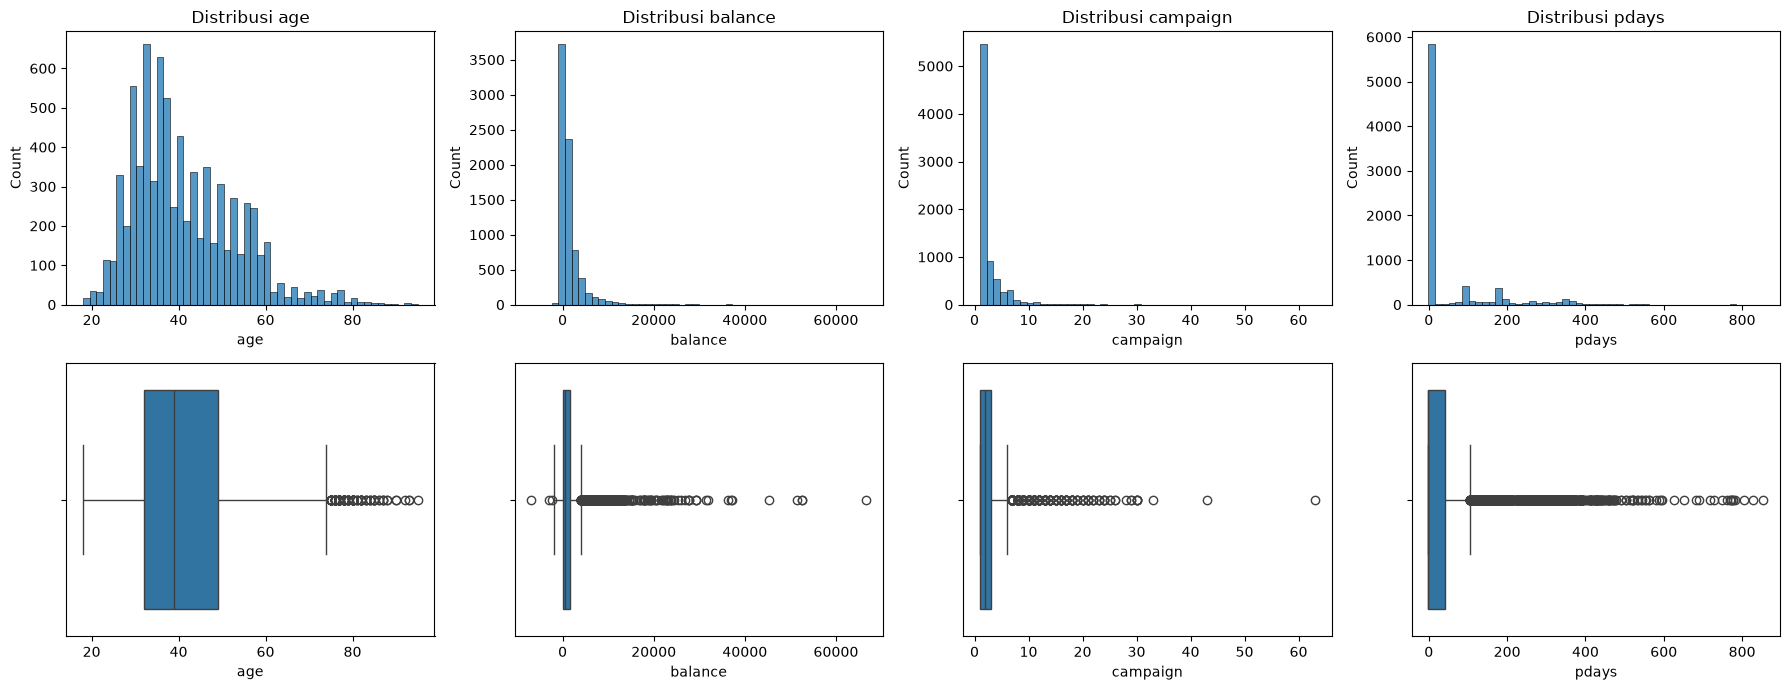

In [16]:
# Melihat distribusi data kolom numerik
num_columns = df.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_columns):
    sns.histplot(df[c], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f'Distribusi {c}')
    sns.boxplot(x=df[c], ax=axes[1, i])
plt.tight_layout()
plt.show()

In [17]:
# Mengecek Jumlah outlier dengan metode IQR
def iqr_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'batas_bawah': lower, 'batas_atas': upper,
                      'jumlah_outlier': ((s < lower) | (s > upper)).sum(),
                      'persen_outlier': round(((s < lower) | (s > upper)).mean() * 100, 2)})

pd.DataFrame({c: iqr_outlier(df[c]) for c in ['age', 'balance', 'campaign']}).T

,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
age,6.5,74.5,121.0,1.55
balance,-2207.5,4020.5,736.0,9.43
campaign,-2.0,6.0,429.0,5.50


In [18]:
# Mengecek jumlah nilai negatif pada kolom balance dan pdays
print('Nasabah dengan balance negatif:', (df['balance'] < 0).sum())
print('Nasabah dengan pdays = -1 (belum pernah dihubungi):', (df['pdays'] == -1).sum(),
      f"({(df['pdays'] == -1).mean():.1%})")

Nasabah dengan balance negatif: 479
Nasabah dengan pdays = -1 (belum pernah dihubungi): 5809 (74.4%)


In [19]:
# Cardinality kolom kategorikal
pd.DataFrame({'cardinality': [df[c].nunique() for c in cat_columns]}, index=cat_columns)

,cardinality
job,12
housing,2
loan,2
contact,3
month,12
poutcome,4


**Insight:**
- **Outlier** pada kolom `balance` (9,43%) dan `campaign` (5,50%) masih memiliki nilai yang masuk akal. Saldo yang besar bersifat wajar untuk nasabah yang kaya dan saldo negatif (479 nasabah) bisa berarti nasabah sedang memiliki pinjaman dan saldonya dipotong untuk membayar cicilan atau rekeningnya *overdraft*.
- Kolom **`age`** berada pada rentang usia 18 sampai 95 tahun adalah kondisi yang wajar.
- **`pdays = -1`** berarti nasabah **belum pernah dihubungi** (74,4% nasabah).
- *Cardinality* pada kolom kategorikal relatif rendah (maksimal 12 kategori) sehingga aman untuk dilakukan *One-Hot Encoding*.

**Keputusan:** outlier **tidak dihapus** karena nilainya valid.

## **Section 4. Exploratory Data Analysis (EDA)**

Sebelum melakukan EDA, data dibagi menjadi **seen (80%)** dan **unseen (20%)** terlebih dahulu dengan stratify pada kolom target agar proporsi `yes`/`no` tetap seimbang. Selanjutnya `df` hanya akan berisi data **seen** yang dipakai untuk EDA, data preparation, dan modeling.

In [20]:
# Memisahkan data seen (untuk EDA & modeling) dan unseen (simulasi bisnis)
df, df_unseen = train_test_split(df, test_size=0.20, stratify=df['deposit'], random_state=RANDOM_STATE)
df = df.reset_index(drop=True)
df_unseen = df_unseen.reset_index(drop=True)

print('Data seen   :', df.shape)
print('Data unseen :', df_unseen.shape)
pd.DataFrame({'seen': df['deposit'].value_counts(normalize=True),
              'unseen': df_unseen['deposit'].value_counts(normalize=True)}).round(4)

Data seen   : (6244, 11)
Data unseen : (1561, 11)


,seen,unseen
deposit,,
no,0.5221,0.5221
yes,0.4779,0.4779


**Insight:**
- Data **seen** berisi **6.244 baris** dan data **unseen** berisi **1.561 baris**.
- Proporsi target di kedua data sama persis (**52,21% `no` : 47,79% `yes`**) karena split memakai stratify.
- Mulai Section 4 seluruh analisis memakai data `seen`.

### *4.1 Univariate Analysis*

In [21]:
df.groupby('deposit')['deposit'].count()

deposit
no     3260
yes    2984
Name: deposit, dtype: int64

Proporsi target positif dan negatif cukup seimbang

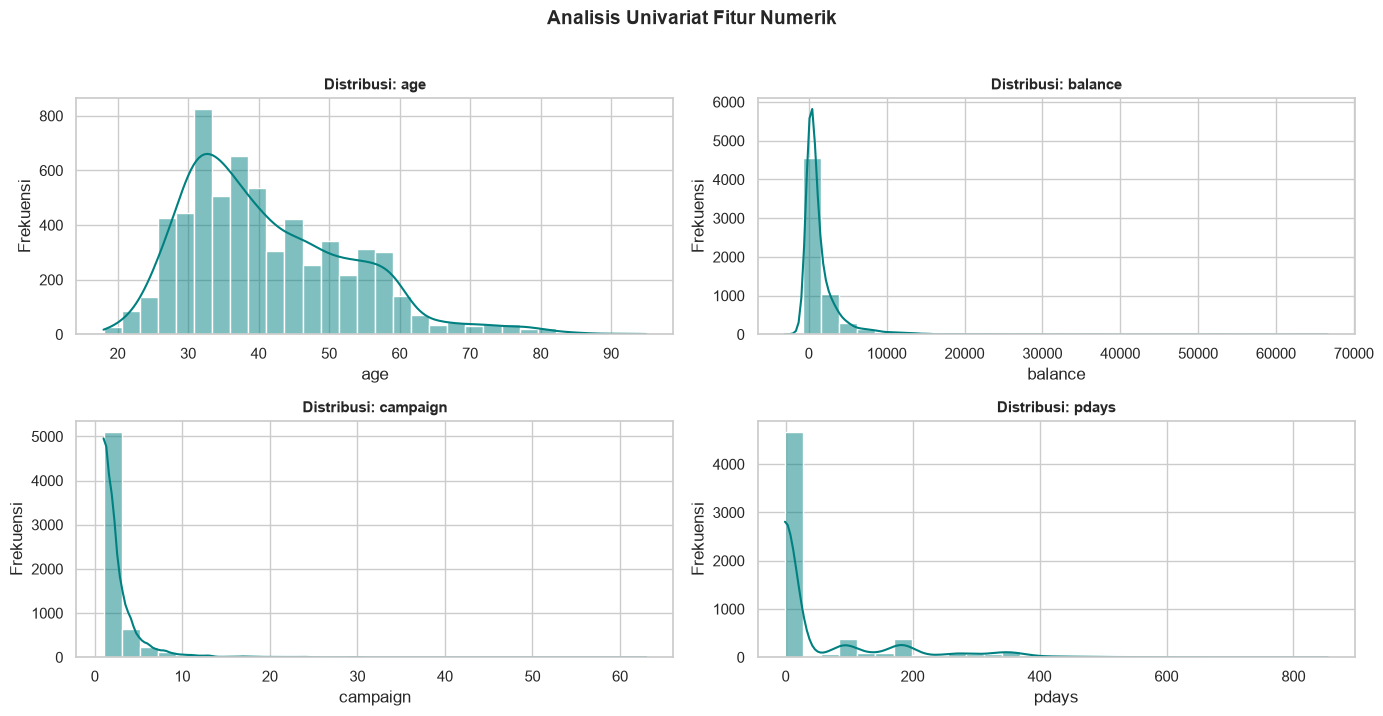

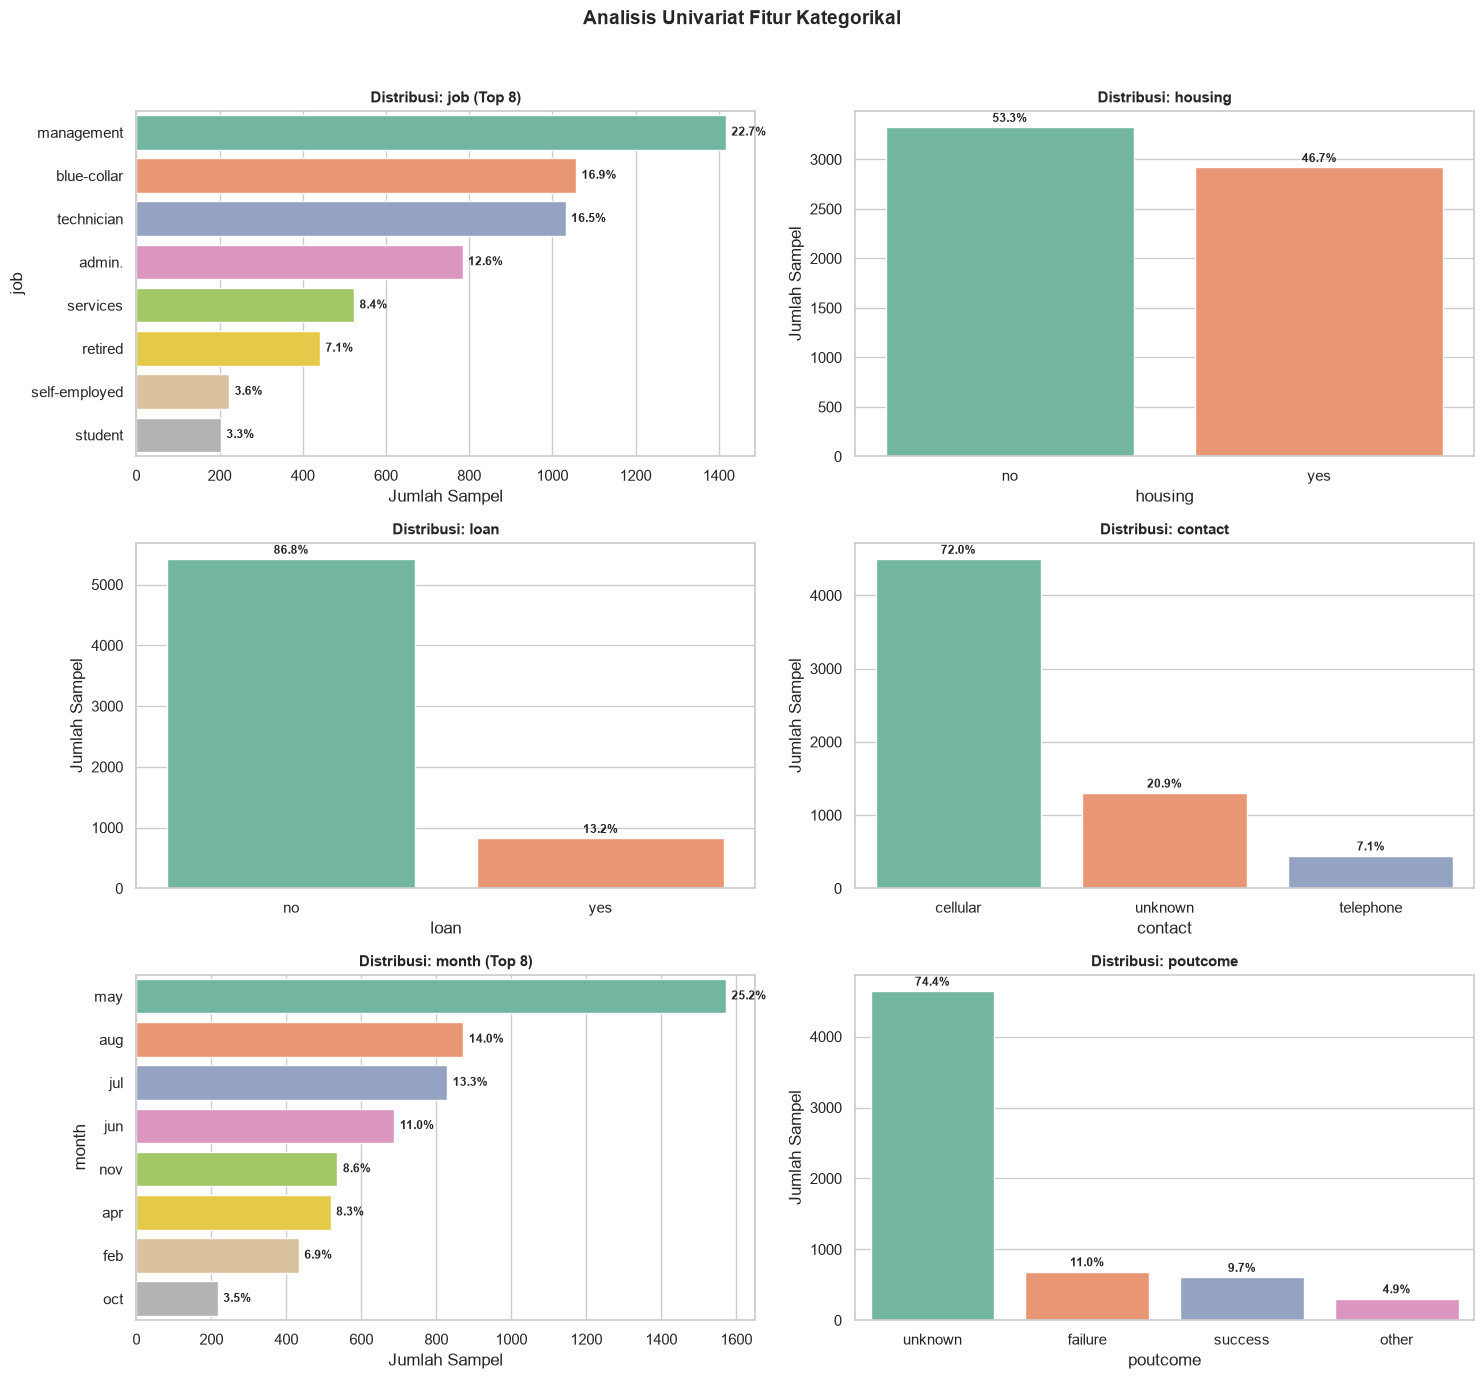

In [22]:
# Set style global
sns.set_theme(style="whitegrid")

# =====================================================================
# 1. SUBPLOT UNIVARIAT NUMERIK (Histogram + KDE)
# =====================================================================
def plot_univariate_num_subplot(df, num_cols):
    n_cols = len(num_cols)
    # Buat grid subplot 2 kolom
    nrows = (n_cols + 1) // 2
    fig, axes = plt.subplots(nrows=nrows, ncols=2, figsize=(14, 3.5 * nrows))
    axes = axes.flatten()
    
    for i, col in enumerate(num_cols):
        sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='teal', bins=30)
        axes[i].set_title(f'Distribusi: {col}', fontsize=11, fontweight='bold')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frekuensi')
        
    # Hapus subplot kosong jika jumlah fitur ganjil
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.suptitle("Analisis Univariat Fitur Numerik", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# =====================================================================
# 2. SUBPLOT UNIVARIAT KATEGORIKAL (Bar Chart + Persentase)
# =====================================================================
def plot_univariate_cat_subplot(df, cat_cols, top_n=8):
    n_cols = len(cat_cols)
    nrows = (n_cols + 1) // 2
    fig, axes = plt.subplots(nrows=nrows, ncols=2, figsize=(15, 4.5 * nrows))
    axes = axes.flatten()
    total_len = len(df)
    
    for i, col in enumerate(cat_cols):
        ax = axes[i]
        order = df[col].value_counts().iloc[:top_n].index
        
        # Plot horizontal jika kategori > 4 agar label rapi
        if df[col].nunique() > 4:
            sns.countplot(data=df, y=col, order=order, ax=ax, palette='Set2')
            for p in ax.patches:
                width = p.get_width()
                if width > 0:
                    pct = f'{(width / total_len) * 100:.1f}%'
                    ax.annotate(pct, (width, p.get_y() + p.get_height() / 2.),
                                ha='left', va='center', fontsize=8.5, fontweight='bold', xytext=(4, 0),
                                textcoords='offset points')
            ax.set_xlabel('Jumlah Sampel')
            ax.set_ylabel(col)
        else:
            sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set2')
            for p in ax.patches:
                height = p.get_height()
                if height > 0:
                    pct = f'{(height / total_len) * 100:.1f}%'
                    ax.annotate(pct, (p.get_x() + p.get_width() / 2., height),
                                ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0, 2),
                                textcoords='offset points')
            ax.set_xlabel(col)
            ax.set_ylabel('Jumlah Sampel')
            
        title_suffix = f' (Top {top_n})' if df[col].nunique() > top_n else ''
        ax.set_title(f'Distribusi: {col}{title_suffix}', fontsize=11, fontweight='bold')
        
    # Hapus subplot kosong jika jumlah fitur ganjil
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.suptitle("Analisis Univariat Fitur Kategorikal", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# =====================================================================
# 3. PANGGUL DALAM 1 LENGKAP NOTEBOOK
# =====================================================================

plot_univariate_num_subplot(df, num_columns)
plot_univariate_cat_subplot(df, cat_columns)

### *4.2 Bivariate Analysis (terhadap Target)*

=== Visualisasi Fitur Numerik vs Target ===


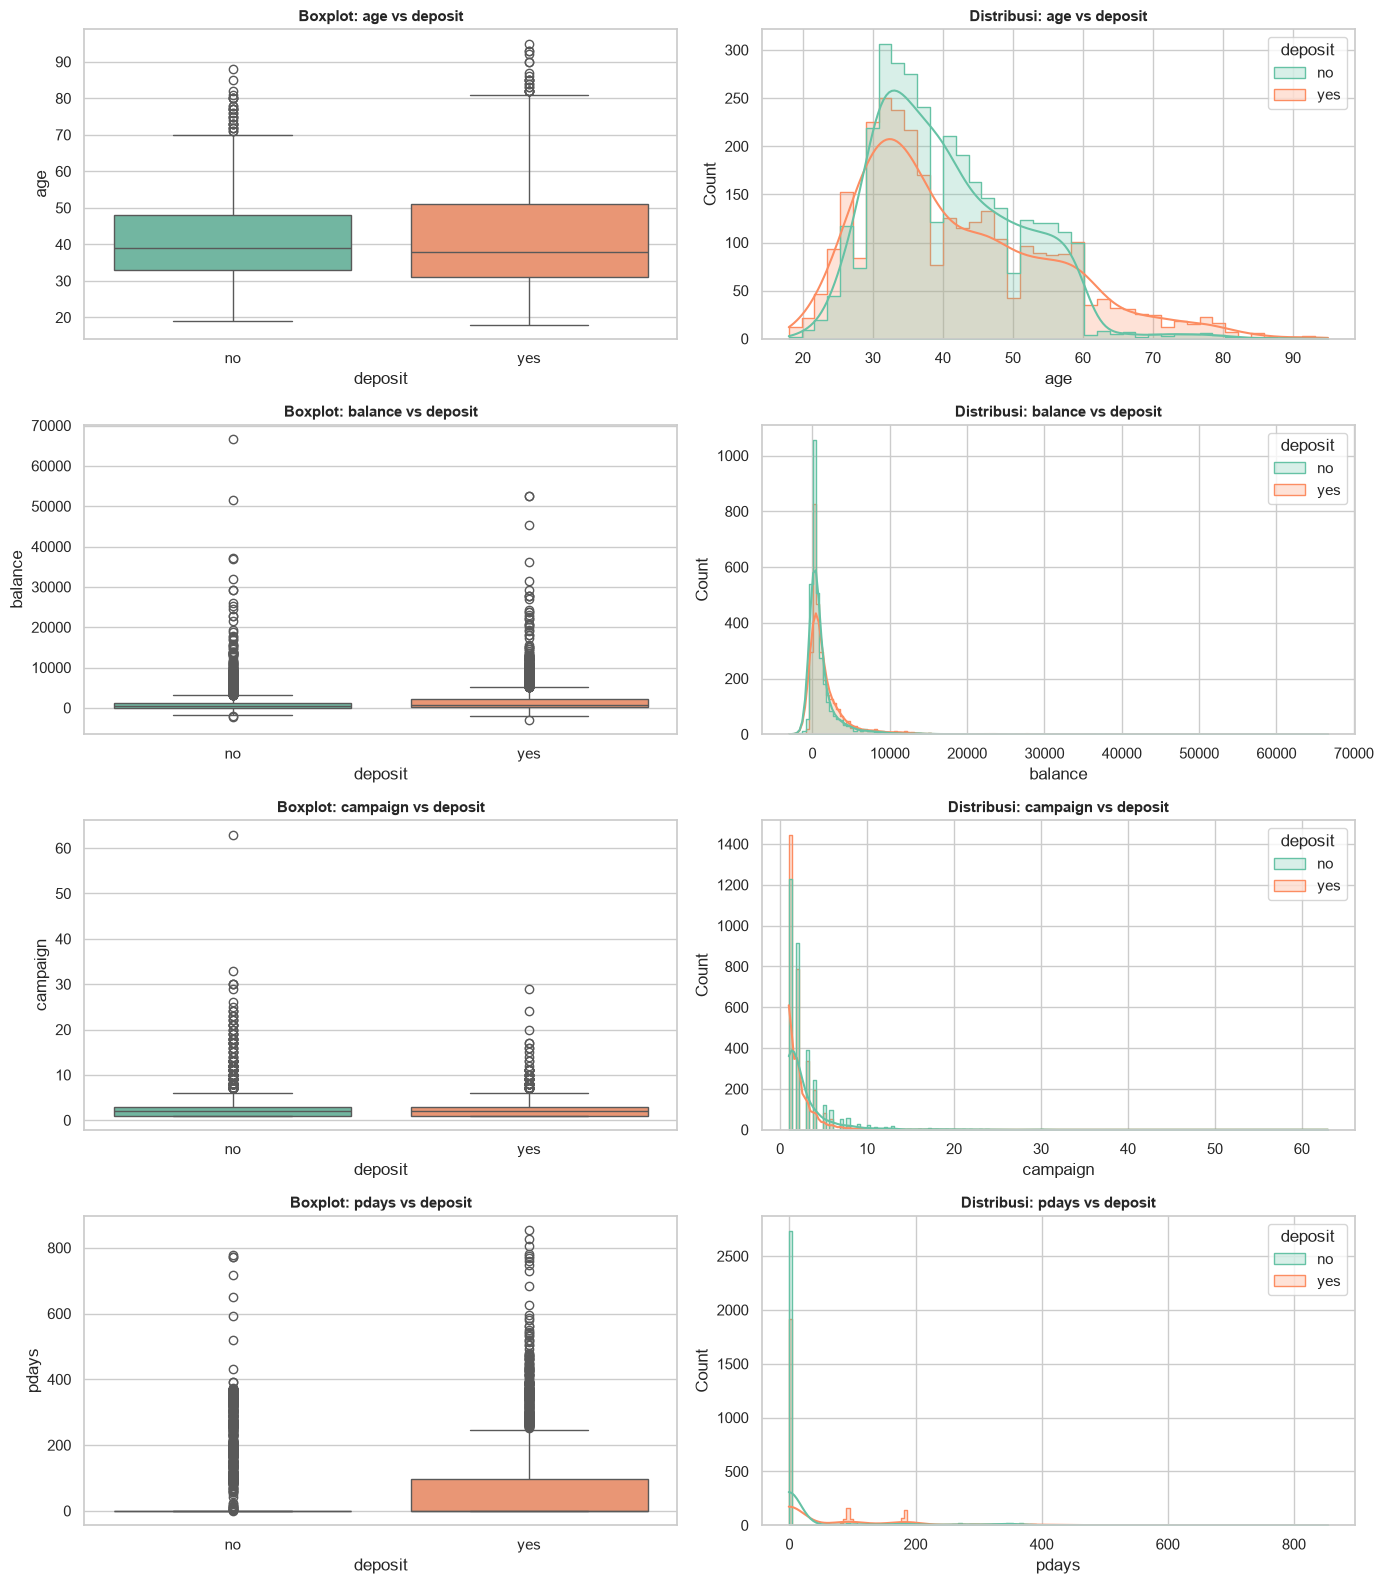

=== Visualisasi Fitur Kategorikal vs Target ===


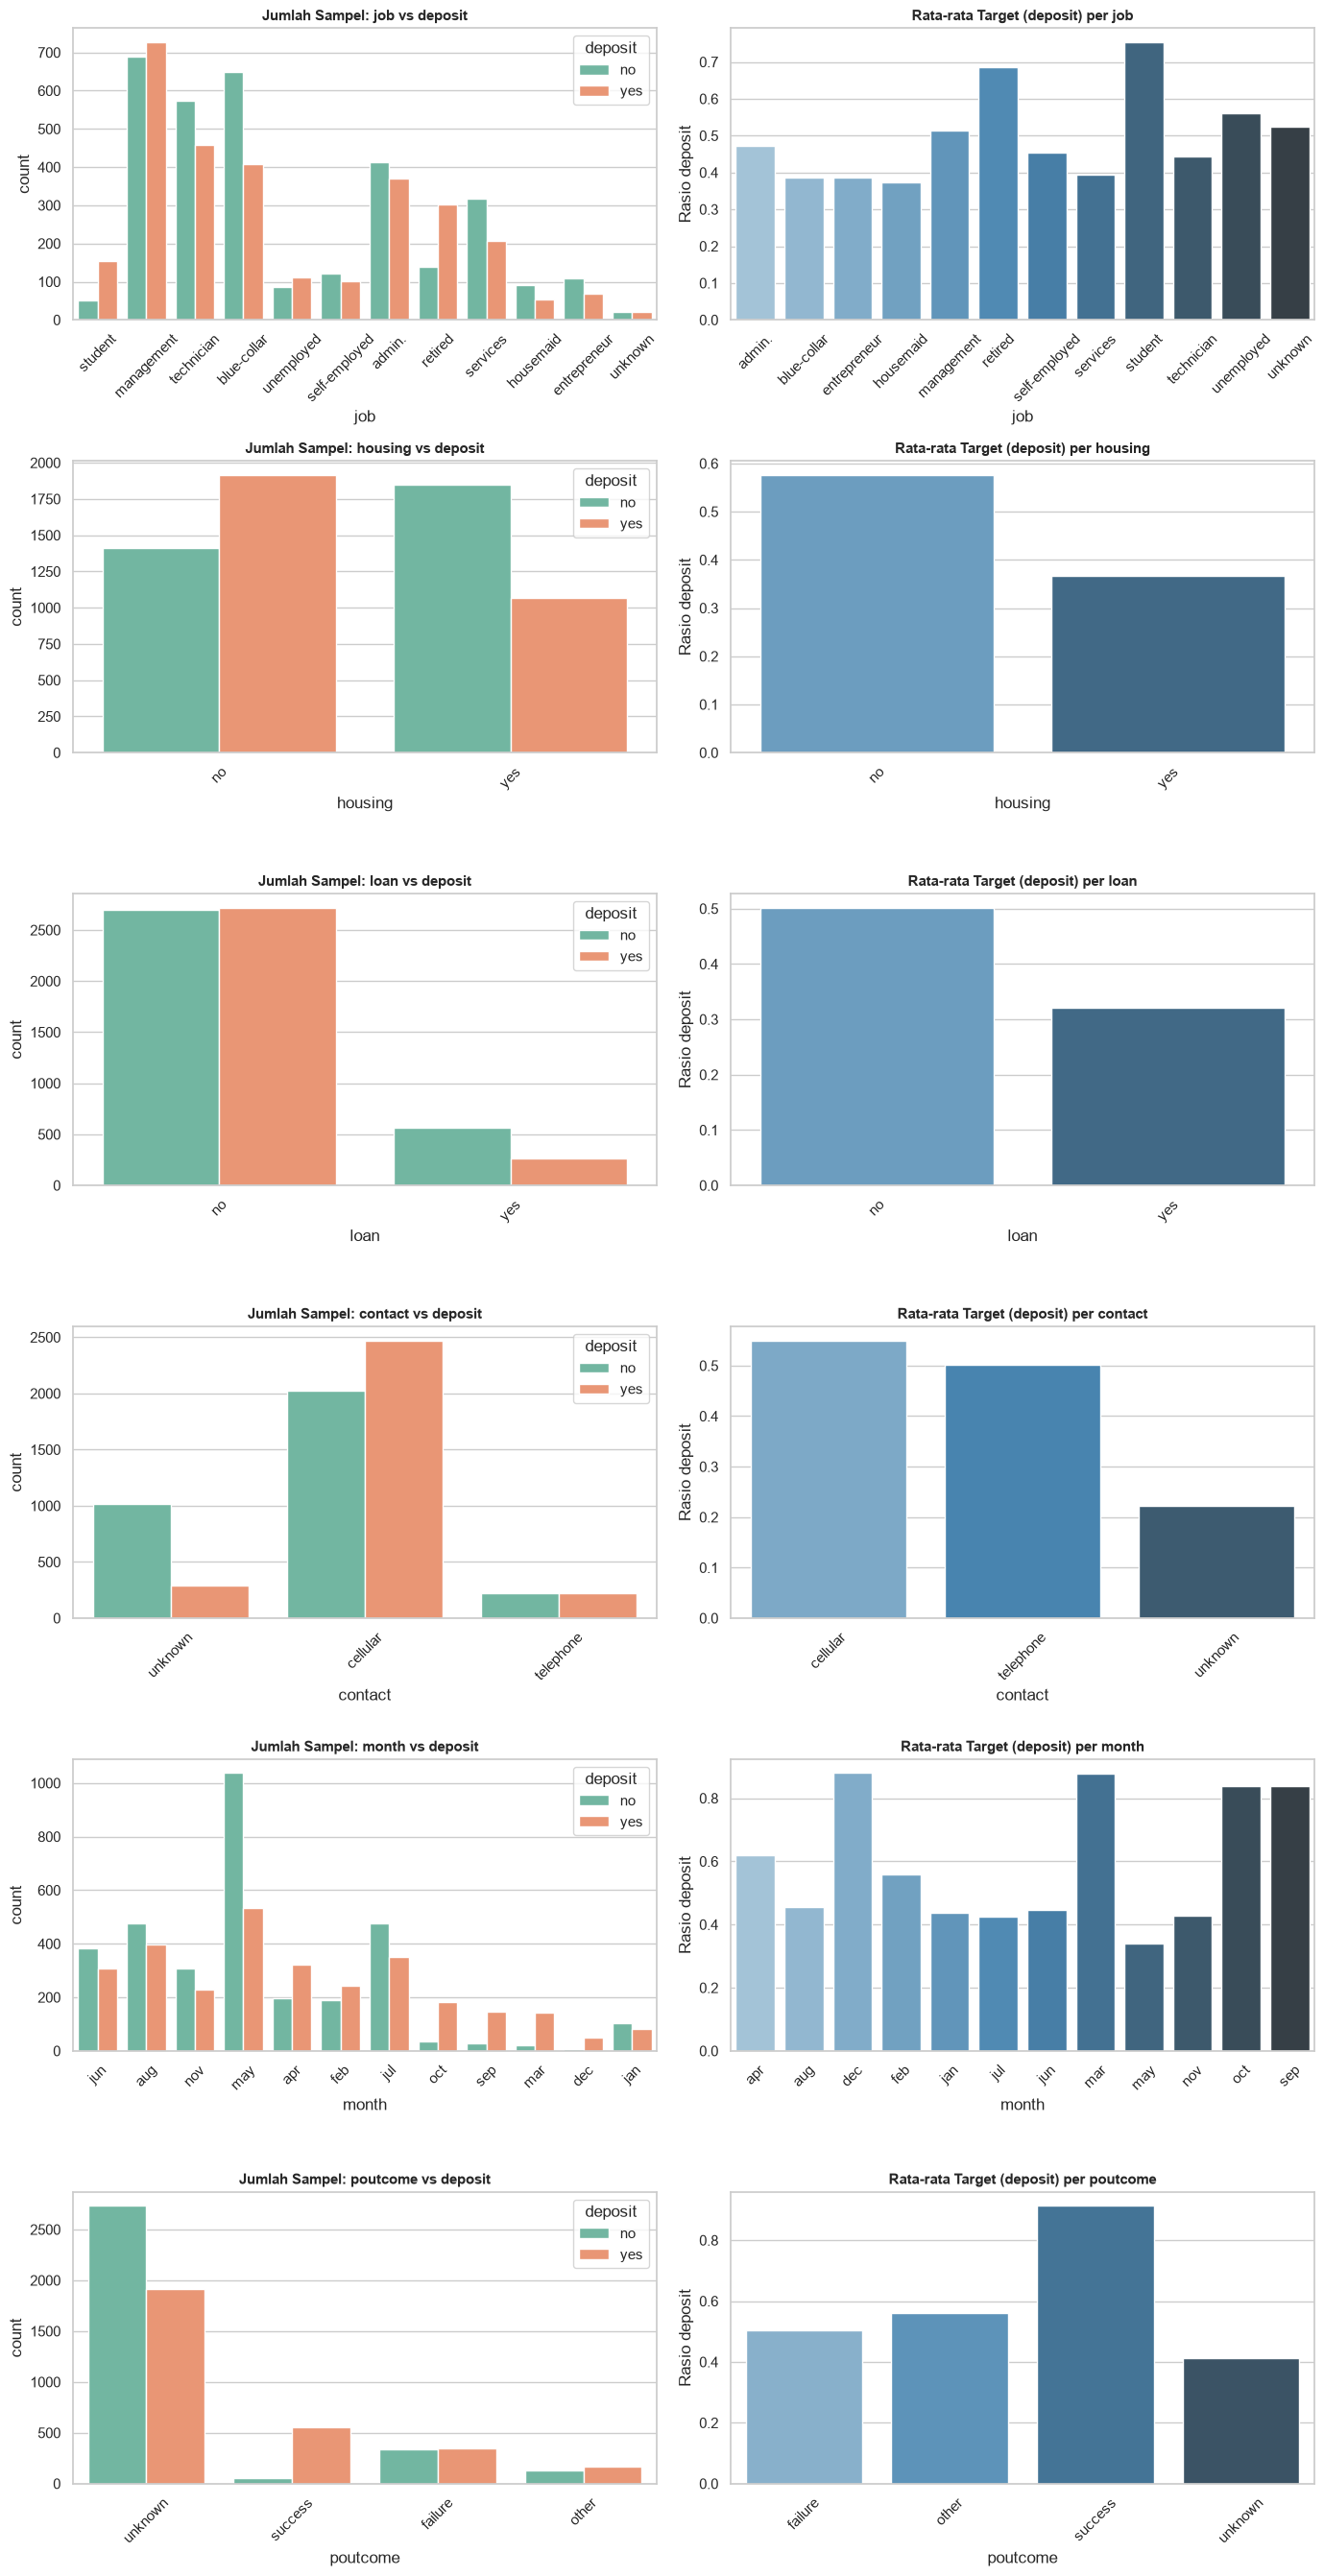

In [23]:
def plot_feature_vs_target(df, target_col, num_features=None, cat_features=None):
    """
    Memvisualisasikan seluruh fitur numerik dan kategorikal terhadap target klasifikasi
    dalam 2 gambar utama (1 figure untuk numerik, 1 figure untuk kategorikal).
    """
    sns.set_theme(style="whitegrid")

    # 1. VISUALISASI FITUR NUMERIK (1 GAMBAR UTAMA)
    if num_features:
        print("=== Visualisasi Fitur Numerik vs Target ===")
        n_num = len(num_features)
        
        # Buat grid subplot (n_num baris x 2 kolom)
        fig, axes = plt.subplots(n_num, 2, figsize=(14, 4 * n_num))
        
        for i, col in enumerate(num_features):
            # Penanganan indexing axes jika n_num = 1 vs n_num > 1
            ax_box = axes[0] if n_num == 1 else axes[i, 0]
            ax_hist = axes[1] if n_num == 1 else axes[i, 1]
            
            # Boxplot: Sebaran & Outlier
            sns.boxplot(data=df, x=target_col, y=col, ax=ax_box, palette="Set2")
            ax_box.set_title(f"Boxplot: {col} vs {target_col}", fontsize=11, fontweight='bold')
            
            # Histplot + KDE: Distribusi Overlap
            sns.histplot(data=df, x=col, hue=target_col, kde=True, ax=ax_hist, palette="Set2", element="step")
            ax_hist.set_title(f"Distribusi: {col} vs {target_col}", fontsize=11, fontweight='bold')
        
        plt.tight_layout()
        plt.show()

    # 2. VISUALISASI FITUR KATEGORIKAL (1 GAMBAR UTAMA)
    if cat_features:
        print("=== Visualisasi Fitur Kategorikal vs Target ===")
        n_cat = len(cat_features)
        
        # Konversi target ke angka (0/1) untuk menghitung rata-rata (target rate) tanpa error 'str'
        df_temp = df.copy()
        target_numeric = pd.to_numeric(df_temp[target_col], errors='coerce')
        if target_numeric.isna().any():
            target_numeric = df_temp[target_col].astype('category').cat.codes
        df_temp['_target_num'] = target_numeric

        # Buat grid subplot (n_cat baris x 2 kolom)
        fig, axes = plt.subplots(n_cat, 2, figsize=(14, 4.5 * n_cat))
        
        for i, col in enumerate(cat_features):
            ax_count = axes[0] if n_cat == 1 else axes[i, 0]
            ax_rate = axes[1] if n_cat == 1 else axes[i, 1]
            
            # Countplot: Jumlah Sampel per Kategori
            sns.countplot(data=df, x=col, hue=target_col, ax=ax_count, palette="Set2")
            ax_count.set_title(f"Jumlah Sampel: {col} vs {target_col}", fontsize=11, fontweight='bold')
            ax_count.tick_params(axis='x', rotation=45)
            
            # Barplot: Target Rate (Rata-rata Target)
            target_rate = df_temp.groupby(col)['_target_num'].mean().reset_index()
            sns.barplot(data=target_rate, x=col, y='_target_num', ax=ax_rate, palette="Blues_d")
            ax_rate.set_title(f"Rata-rata Target ({target_col}) per {col}", fontsize=11, fontweight='bold')
            ax_rate.set_ylabel(f"Rasio {target_col}")
            ax_rate.tick_params(axis='x', rotation=45)
            
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------
# PENGGUNAAN:
# ---------------------------------------------------------
plot_feature_vs_target(df=df, target_col='deposit', num_features=num_columns, cat_features=cat_columns)

Insight Feature Numerik: 
- `pdays` memiliki pola korelasi dengan Target dimana nasabah melakukan deposit lebih banyak yang `pdays` > 0 atau pernah dihubungi pada campaign sebelumnya (67% deposit, dibanding 41% untuk yang belum pernah dihubungi)
- usia > 60 cenderung melakukan deposit (84%)

Insight Feature Categorical:
- `job` dengan rata-rata deposit diatas 50% (Student, Retired, Unemployed, dan Management)
- `housing` (no) memiliki rata-rata sekitar 58% rasio deposit disbanding `housing` (yes) dengan rata-rata 37%
- `loan` (no) rasio deposit cukup setara, namun loan(yes) cenderung tidak deposit
- `month` (Desember, Maret, Oktober, September dan April) memiliki rasio deposit diatas 60%
- `poutcome` Success cenderung deposit, tapi `poutcome` unknown(tidak dihubungi di campaign sebelum) cenderung tidak deposit


### *4.3 Correlation & Multicollinearity Check*

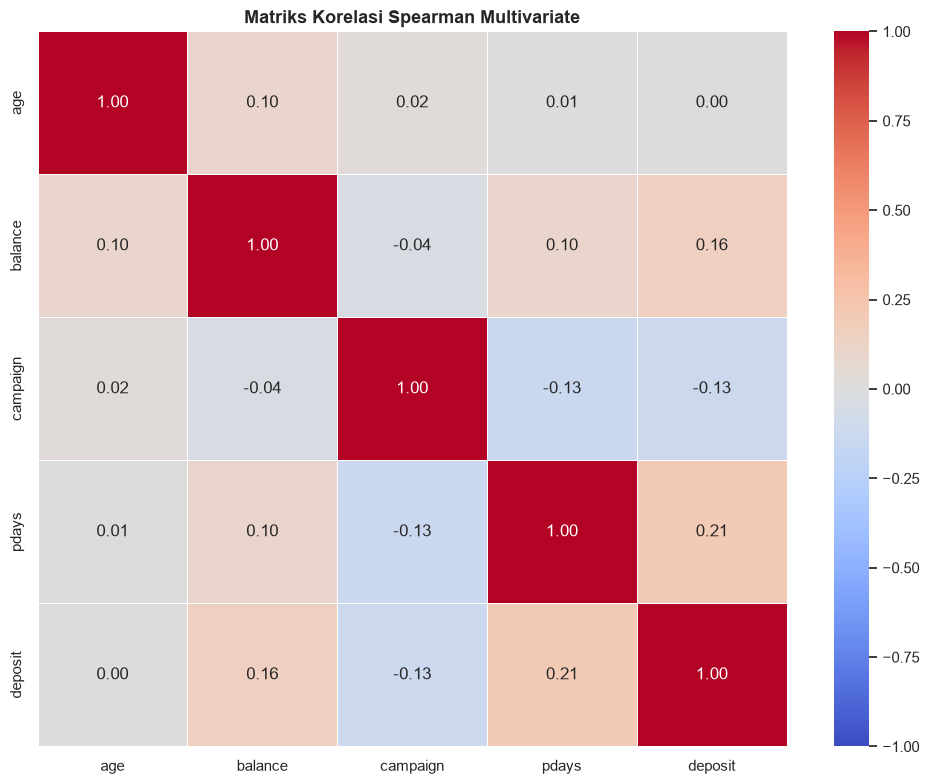

In [24]:
# ---------------------------------------------------------
# 1. MATRIKS KORELASI MULTIVARIATE (Korelasi Spearman)
# ---------------------------------------------------------
def plot_correlation_heatmap(df, target_col):
    """Menampilkan peta korelasi antar seluruh fitur numerik dan target."""
    plt.figure(figsize=(10, 8))
    df_num = df.select_dtypes(include=[np.number]).copy()
    
    if target_col in df.columns and df[target_col].dtype == object:
        df_num[target_col] = df[target_col].map({'no': 0, 'yes': 1})
        
    corr = df_num.corr(method='spearman')  # Spearman menangkap hubungan monotonik non-linier
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
    plt.title("Matriks Korelasi Spearman Multivariate", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

df_viz = df.copy()
df_viz['deposit'] = df_viz['deposit'].map({'no': 0, 'yes': 1})
# 1. Korelasi Spearman antar fitur numerik dan target
plot_correlation_heatmap(df=df_viz, target_col='deposit')

Insight: Tidak ada korelasi yang menggangu antar feature

### *4.4 Multivariate / Interaction Analysis (opsional)*

Interpretasi (Matriks Korelasi Spearman Multivariate): 
- `pdays` ($r = 0.21$): Memiliki korelasi paling tinggi di antara fitur numerik lainnya, namun skalanya masih tergolong lemah ke sedang. (Artinya semakin lama jeda dari kampanye sebelumnya/pernah dihubungi sebelumnya, kecenderungan deposit sedikit meningkat).
- `balance` ($r = 0.16$): Memiliki korelasi positif yang lemah. Saldo yang tinggi ada kecenderungan positif terhadap deposit, tetapi tidak linier/monotonik kuat.   
- `campaign` ($r = -0.13$): Memiliki korelasi negatif yang lemah. Semakin sering dihubungi di kampanye saat ini, peluang deposit justru sedikit menurun (gejala kelelahan kontak / fatigue)

Insight: 
Nilai korelasi individual yang lemah ($< 0.25$) membuktikan secara statistik bahwa fitur numerik bawaan tidak memiliki sinyal linear/monotonik yang cukup kuat untuk memisahkan kelas positif dan negatif secara ekstrem. Ini alasan utama mengapa model dasar sempat "bingung" dan banyak menumpuk prediksi di area tengah.

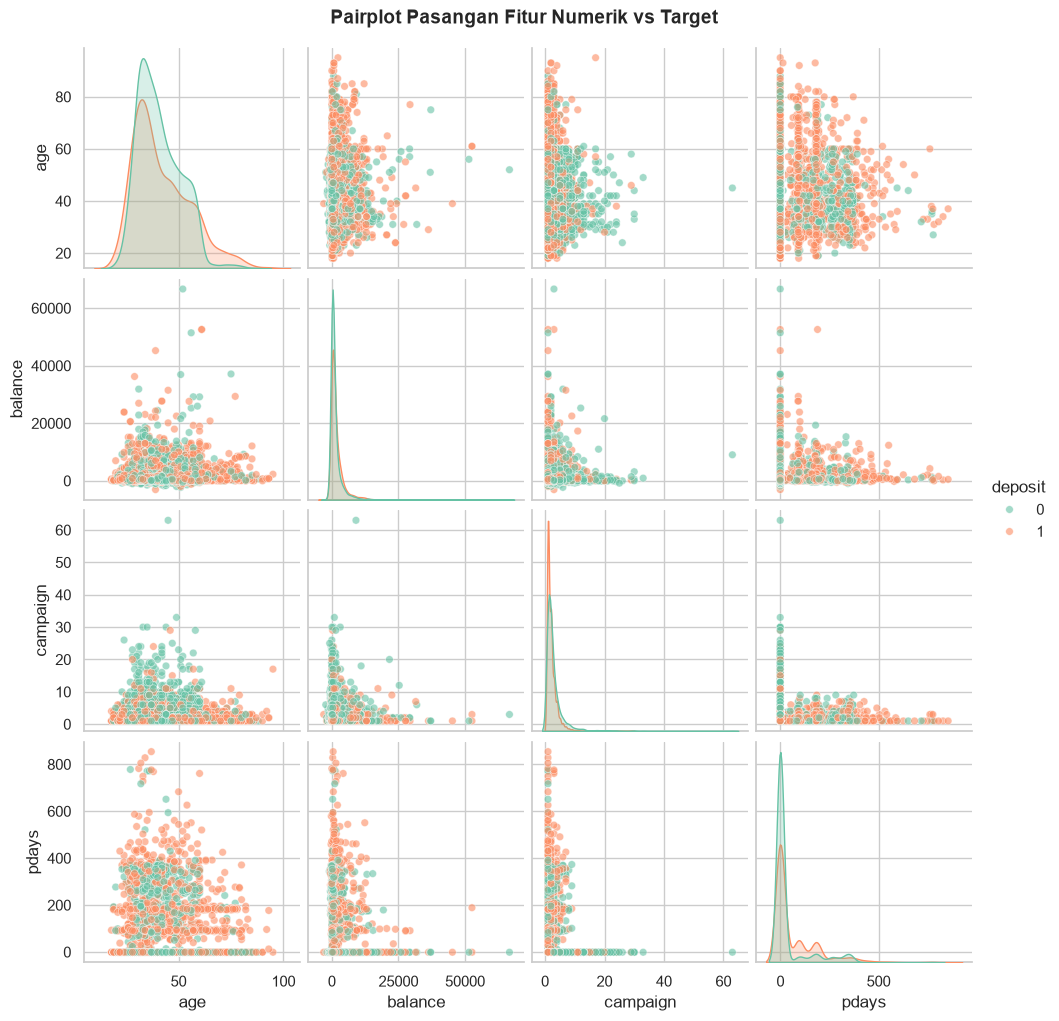

In [25]:
# ---------------------------------------------------------
# 2. PAIRPLOT (Matriks Pasangan Fitur Numerik vs Target)
# ---------------------------------------------------------
def plot_multivariate_pairplot(df, num_features, target_col):
    """Visualisasi gabungan scatter plot & KDE antar pasangan fitur numerik berlabel target."""
    g = sns.pairplot(
        df[num_features + [target_col]], 
        hue=target_col, 
        palette="Set2", 
        diag_kind="kde",
        plot_kws={'alpha': 0.6, 's': 30}
    )
    g.fig.suptitle("Pairplot Pasangan Fitur Numerik vs Target", y=1.02, fontsize=14, fontweight='bold')
    plt.show()

# 2. Pairplot 4 fitur numerik utama
plot_multivariate_pairplot(df=df_viz, num_features=num_columns, target_col='deposit')

Insight: Interaksi Multivariat fitur numerik tidak terdapat pola yang jelas atau sinyal yang jelas yang memisahkan antara deposit dan tidak.

In [26]:

# ---------------------------------------------------------
# 3. INTERAKSI KATEGORIKAL (Pivot Heatmap: Fitur A x Fitur B vs Target Rate)
# ---------------------------------------------------------
def plot_categorical_interaction_heatmap(df, cat_col1, cat_col2, target_col):
    """Melihat rasio deposit untuk kombinasi dua fitur kategorikal sekaligus."""
    df_temp = df.copy()
    if df_temp[target_col].dtype == object:
        df_temp['_target_num'] = df_temp[target_col].map({'no': 0, 'yes': 1})
    else:
        df_temp['_target_num'] = df_temp[target_col]
        
    pivot_table = df_temp.pivot_table(index=cat_col1, columns=cat_col2, values='_target_num', aggfunc='mean')
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot_table, annot=True, fmt=".2%", cmap="Blues", cbar_kws={'label': f'Rasio {target_col}'})
    plt.title(f"Target Rate Heatmap Interaksi: {cat_col1} x {cat_col2}", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

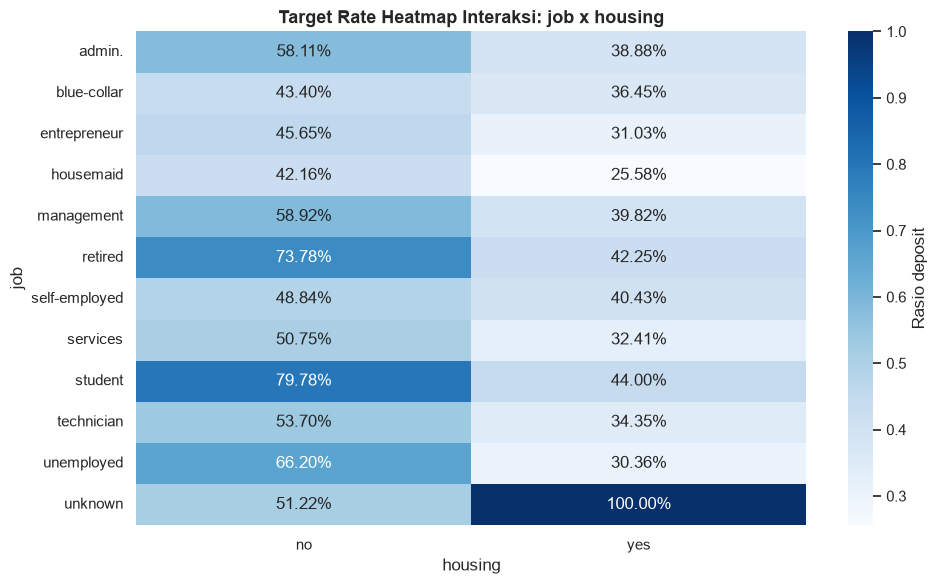

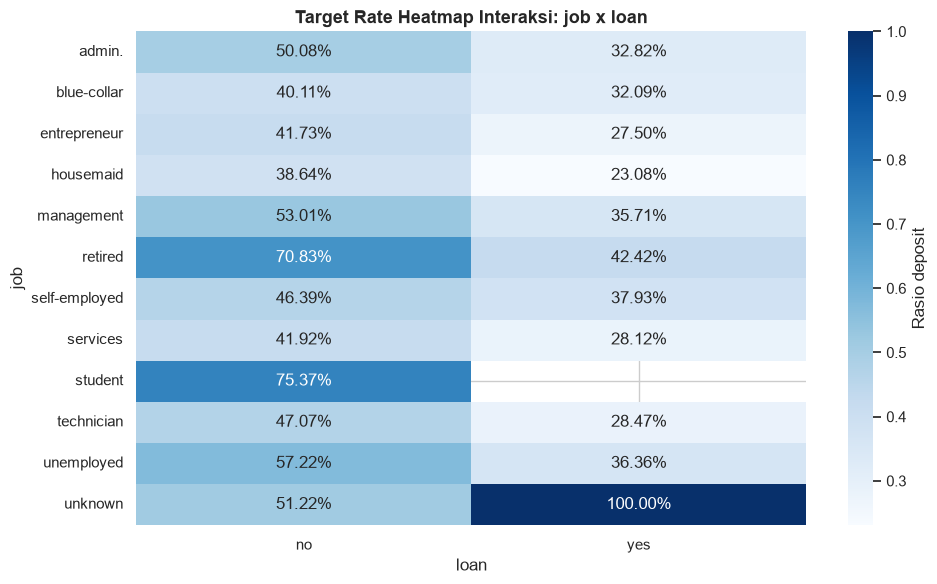

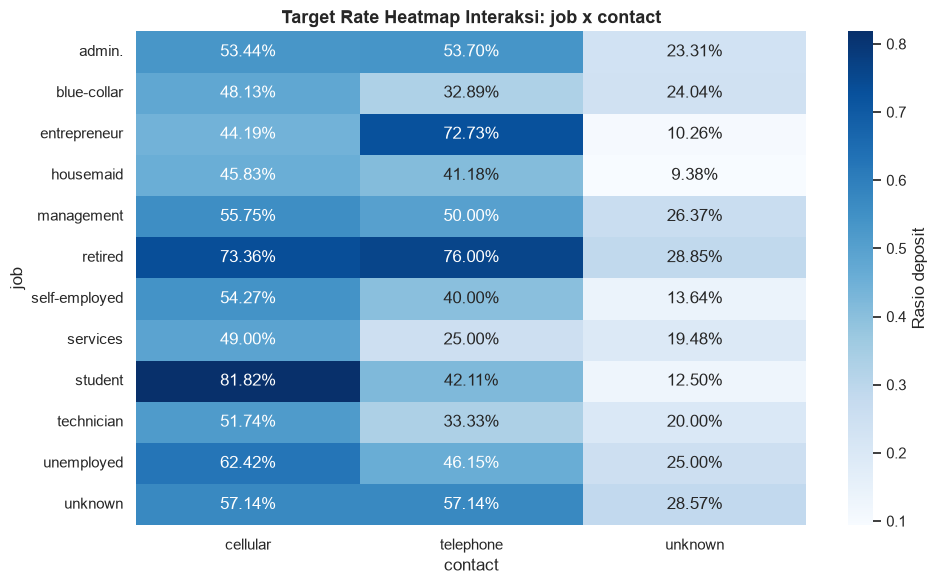

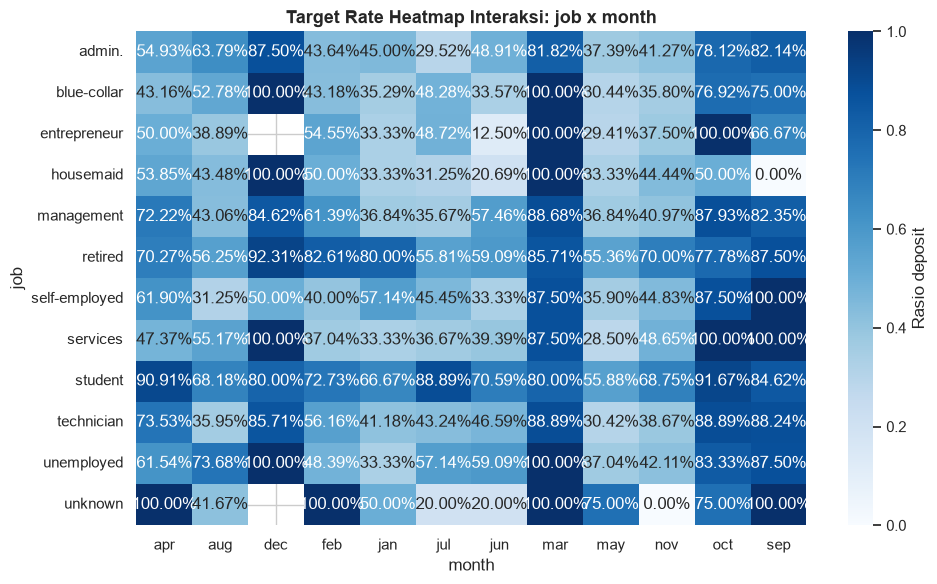

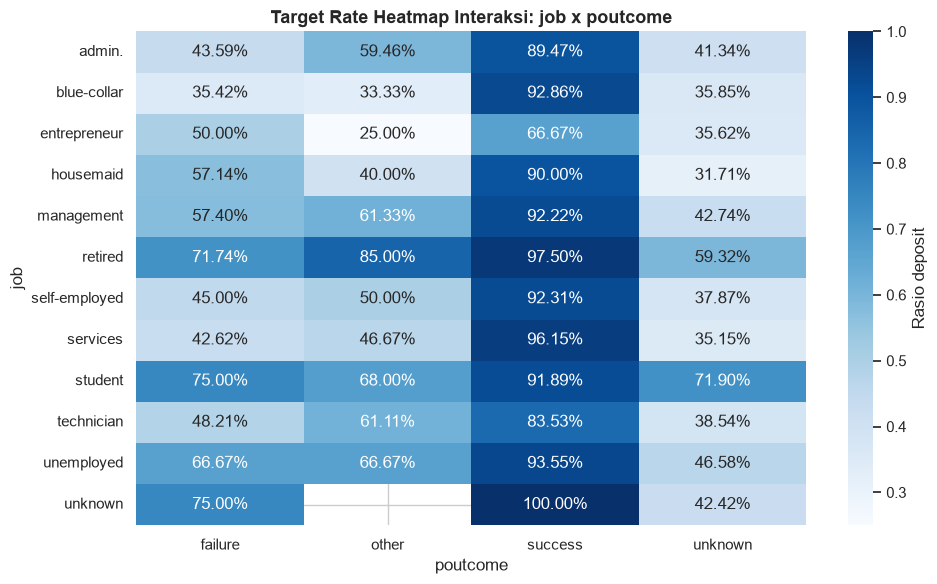

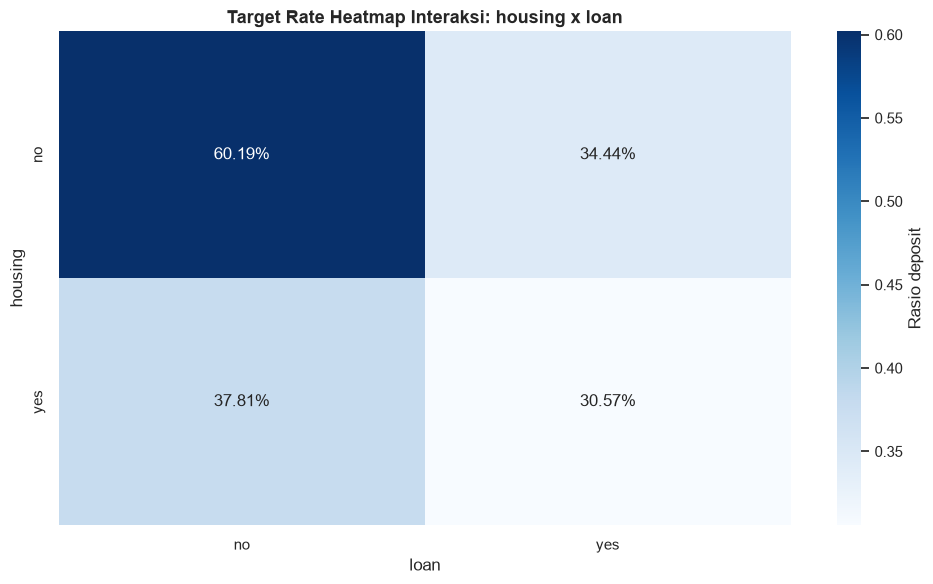

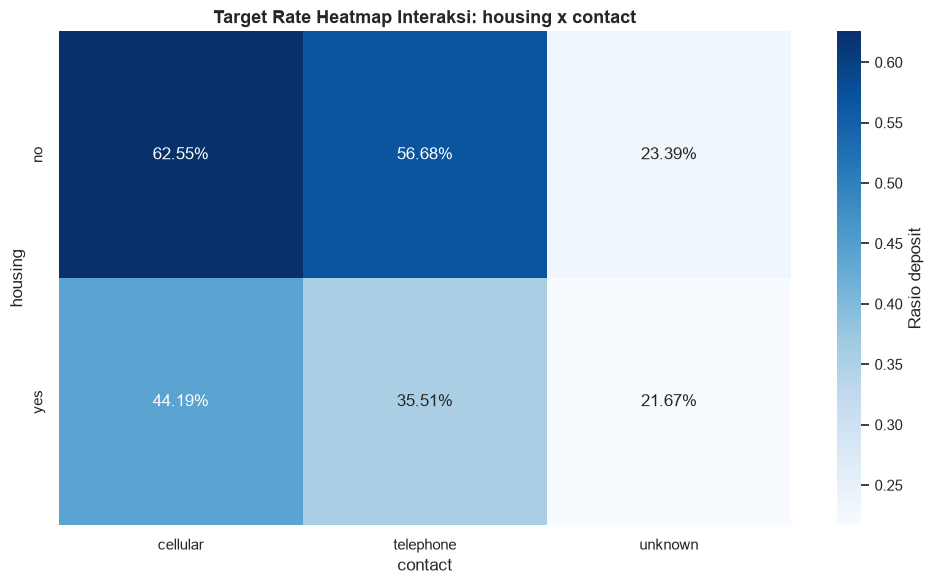

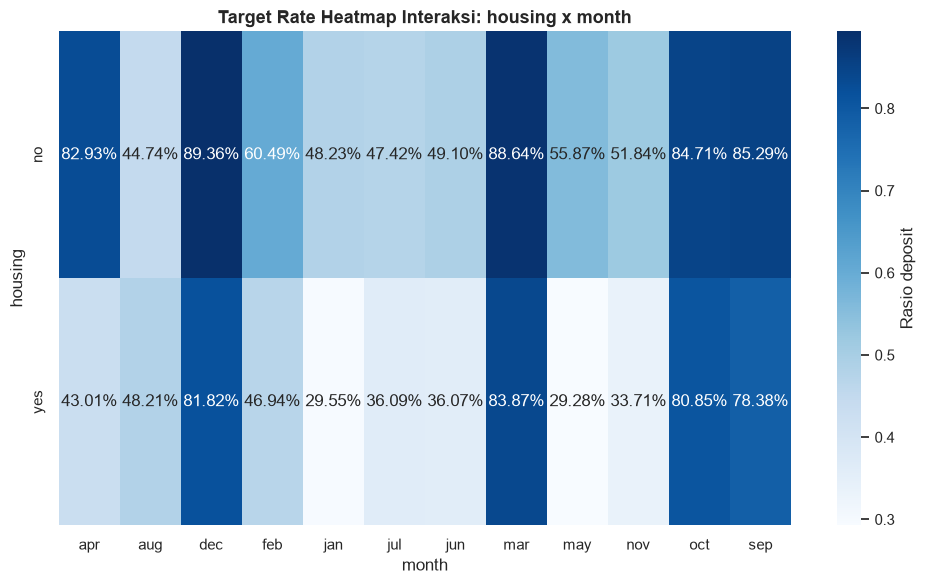

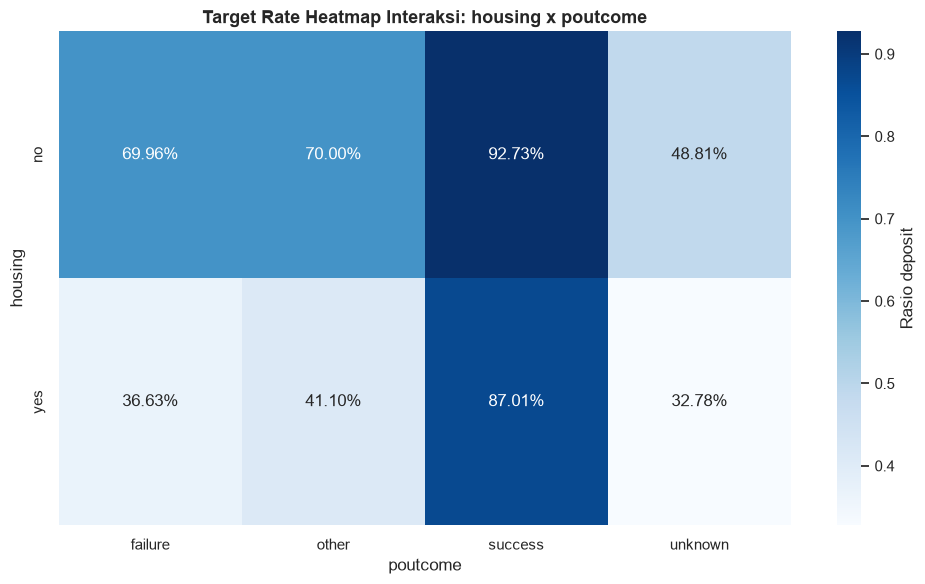

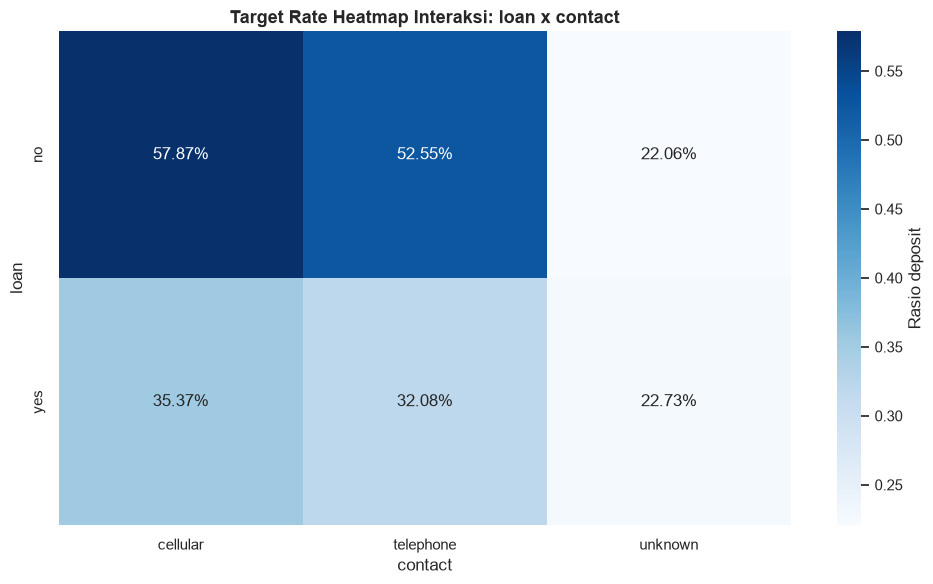

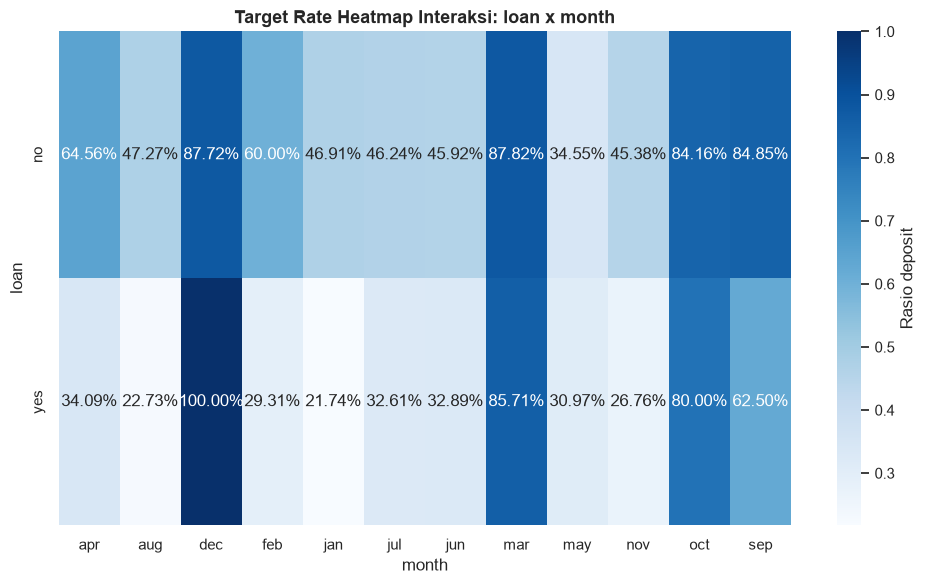

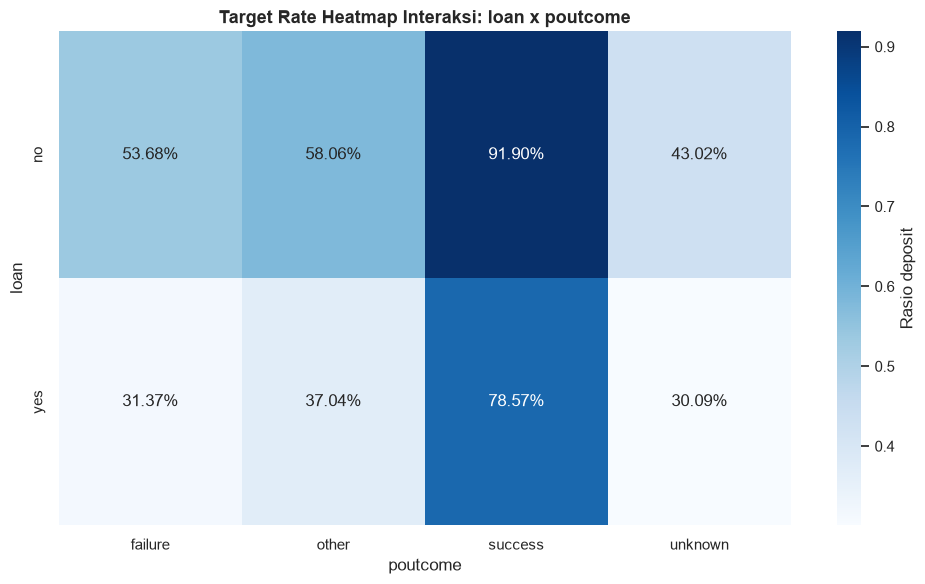

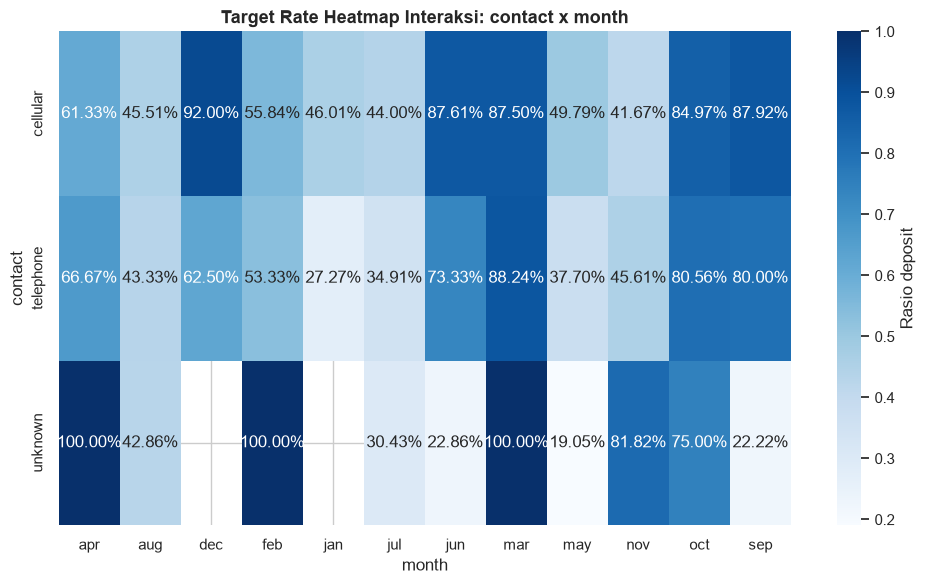

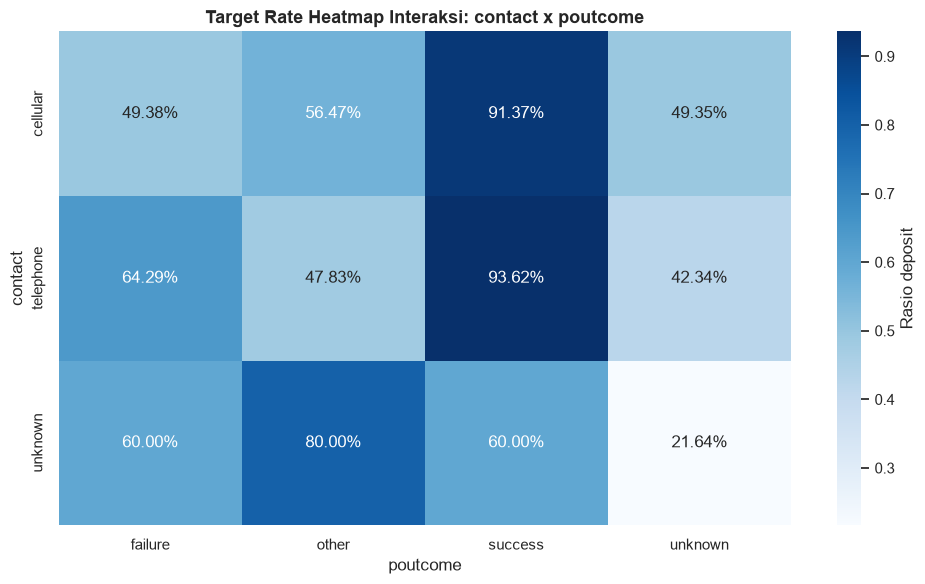

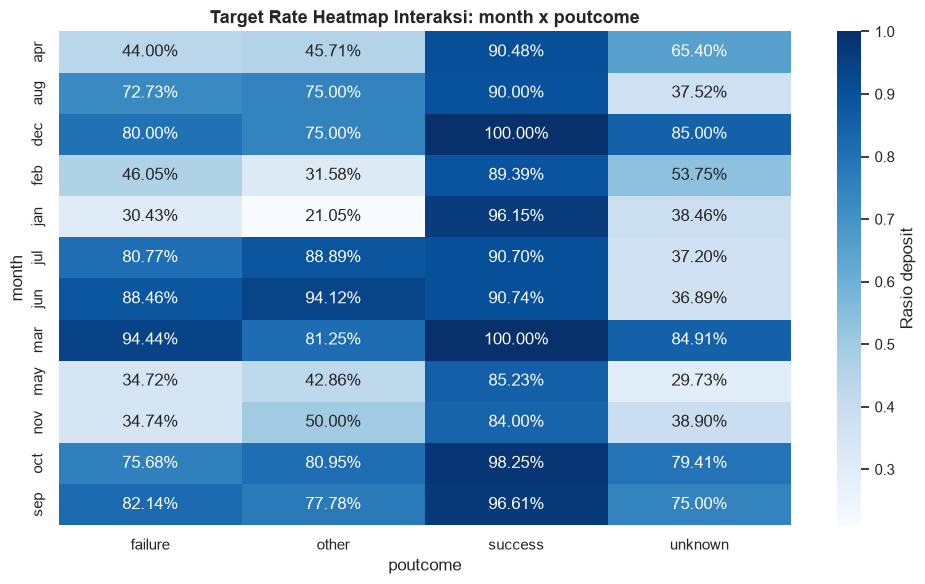

In [27]:
for i in range(len(cat_columns)):
    for j in range(i + 1, len(cat_columns)):
        cat_col1 = cat_columns[i]
        cat_col2 = cat_columns[j]
        plot_categorical_interaction_heatmap(df=df_viz, cat_col1=cat_col1, cat_col2=cat_col2, target_col='deposit')

**Kombinasi yang memiliki rasio deposit tinggi dan bisa digunakan untuk feature baru**
- housing_no_retired = 74%
- housing_no_student = 80%
- housing_no_unemployed = 66%

- student_cellular = 82%
- retired_cellular = 73%
- retired_telepone = 76%
- student_unknown = 13% (hanya 8 nasabah)
- unemployed cellular = 62%

- housing_no_loan_no = 60%

- housing_no_cellular = 63%

- housing_no_failure = 70%
- housing_no_other = 70%
- housing_no_success = 93%
- housing_yes_success = 87%

- loan_no_success = 92%
- loan_yes_failure = 31% (rendah)

- success_cellular = 91%
- success_telepone = 94%
- other_unknown = 80% (hanya 5 nasabah)

- month semua data hot ada di bulan dec, mar, oct, dan sep

**Insight: (kelompok berpengaruh)**
- Super Hot Lead (Sinyal Sukses Riwayat & Bulan Emas) = ['dec', 'mar', 'oct', 'sep']
- Segmen Bebas Beban Finansial (Low Burden Lead) = ['retired', 'student', 'unemployed']
- Job x Contact
- housing x poutcome

## **Section 5. Data Preparation**

### *5.1 Initialization*

In [28]:
# Define feature and target
x = df.drop(columns='deposit')
y = df['deposit'].map({'no': 0, 'yes': 1})

### *5.2 Constructing `Training` and `Testing` Data (from `seen` data)*

In [29]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# Reset Index
x_train.reset_index(drop=True, inplace=True)
x_test.reset_index(drop=True, inplace=True)
y_train.reset_index(drop=True, inplace=True)
y_test.reset_index(drop=True, inplace=True)

# Overview
print('Feature shape (train) : ', x_train.shape)
print('Target shape (train) : ', y_train.shape)

Feature shape (train) :  (4995, 10)
Target shape (train) :  (4995,)


### *5.3 Handling Imbalanced Data*

In [30]:
y_train.value_counts(normalize=True).rename('proporsi').to_frame()

,proporsi
deposit,
0,0.522122
1,0.477878


**Insight:** proporsi kelas di data training sekitar **52:48**, jadi data **relatif seimbang**. Teknik seperti SMOTE atau undersampling tidak diperlukan.

### *5.4 Data Transformation (Feature Engineering)*

In [31]:
# Kelompok fitur
nominal_features   = ['job', 'housing', 'loan', 'contact', 'month']
numerical_features = ['balance', 'campaign']
pdays_features     = ['pdays']
binning_features   = ['age']
ordinal_features   = ['poutcome']

# Create preprocessing Pipeline

# Pipeline - Kategorikal Nominal
nominal_pipeline = Pipeline(steps=[
    ('feature_imputation', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('feature_encoding', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# Pipeline - Numerical
numerical_pipeline = Pipeline(steps=[
    ('feature_imputation', SimpleImputer(strategy='median')),
    ('feature_scaling', RobustScaler())
])

# Pipeline - pdays (+ kolom penanda "belum pernah dihubungi")
pdays_pipeline = Pipeline(steps=[
    ('feature_imputation', SimpleImputer(strategy='constant', fill_value=-1)),
    ('never_contacted_flag', SimpleImputer(missing_values=-1, strategy='constant',
                                           fill_value=-1, add_indicator=True)),
    ('feature_scaling', RobustScaler())
])

# Pipeline - Numerical Binning
binning_pipeline = Pipeline(steps=[
    ('feature_imputation', SimpleImputer(strategy='median')),
    ('feature_binning', KBinsDiscretizer(n_bins=5, strategy='quantile', encode='onehot-dense', random_state=RANDOM_STATE))
])

# Pipeline - Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('feature_imputer', SimpleImputer(strategy='most_frequent')),
    ('feature_encoder', OrdinalEncoder(
        categories=[
            ['unknown', 'other', 'failure', 'success']
        ],
        handle_unknown='use_encoded_value', unknown_value=-1
    )),
])

# Gabungkan semua pipeline
preprocessor = ColumnTransformer(transformers=[
    ('categorical_nominal', nominal_pipeline, nominal_features),
    ('numerical', numerical_pipeline, numerical_features),
    ('pdays', pdays_pipeline, pdays_features),
    ('ordinal', ordinal_pipeline, ordinal_features),
    ('binning', binning_pipeline, binning_features)
], remainder='drop', verbose_feature_names_out=False).set_output(transform='pandas')

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_nominal', ...), ('numerical', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for fe

In [32]:
# class BusinessMultivariateEngineer(BaseEstimator, TransformerMixin):
#     def __init__(self):
#         pass
        
#     def fit(self, X, y=None):
#         return self
        
#     def transform(self, X):
#         X_out = X.copy()
        
#         # HANYA SIMPAN INDIKATOR BINER SPESIFIK INI (Hapus job_contact & housing_poutcome)
#         golden_months = ['dec', 'mar', 'oct', 'sep']
#         X_out['is_super_hot_lead'] = (
#             (X_out['poutcome'] == 'success') | 
#             (X_out['month'].isin(golden_months) & (X_out['contact'] == 'cellular'))
#         ).astype(int)
        
#         free_loan_jobs = ['retired', 'student', 'unemployed']
#         X_out['is_liquid_prospect'] = (
#             (X_out['housing'] == 'no') & 
#             (X_out['loan'] == 'no') & 
#             (X_out['job'].isin(free_loan_jobs))
#         ).astype(int)
        
#         X_out['is_high_risk_contact'] = (
#             (X_out['contact'] == 'unknown') & 
#             (X_out['job'].isin(['student', 'unemployed']))
#         ).astype(int)
        
#         return X_out

In [33]:
# Kolom nominal kembalikan ke fitur asli saja 
# 1. Pakai OneHotEncoder untuk SELURUH fitur kategorikal nominal
# nominal_cols = ['job', 'housing', 'loan', 'contact', 'month', 'poutcome']
# binary_engineered_cols = ['is_super_hot_lead', 'is_liquid_prospect', 'is_high_risk_contact']

# preprocessor = ColumnTransformer(
#     transformers=[
#         # Satu-kan semua fitur kategorikal asli di OneHotEncoder
#         ('categorical_nominal', nominal_pipeline, nominal_cols),
        
#         # Fitur biner turunan multivariate langsung passthrough
#         ('binary_features', 'passthrough', binary_engineered_cols),
        
#         # Pipelines numerik & khusus
#         ('numerical', numerical_pipeline, ['balance', 'campaign']),
#         ('pdays', pdays_pipeline, ['pdays']),
#         ('binning', binning_pipeline, ['age'])
#     ], 
#     remainder='drop', 
#     verbose_feature_names_out=False
# ).set_output(transform='pandas')

# full_preprocessing_pipeline = Pipeline([
#     ('feature_engineering', BusinessMultivariateEngineer()),
#     ('preprocessor', preprocessor)
# ])

Penambahan fiture berdasarkan analisis multivariat tidak memberikan efek pada performa model

Occam’s Razor: Jika penambahan kompleksitas tidak meningkatkan performa, pilihlah model yang lebih sederhana.

### *5.5 Feature Selection*

In [34]:
# Fitur yang dipakai model
print('Fitur numerik  :', num_columns)
print('Fitur kategori :', cat_columns)

Fitur numerik  : ['age', 'balance', 'campaign', 'pdays']
Fitur kategori : ['job', 'housing', 'loan', 'contact', 'month', 'poutcome']


### *5.6 Overview*

In [35]:
print('Data training :', x_train.shape)
print('Data testing  :', x_test.shape)
print('Data unseen   :', df_unseen.drop(columns='deposit').shape)

Data training : (4995, 10)
Data testing  : (1249, 10)
Data unseen   : (1561, 10)


In [36]:
# Fitting to Data Train
preprocessor.set_output(transform='pandas')
preprocessor.fit(x_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_nominal', ...), ('numerical', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for fe

In [37]:
# Transform train and test set
x_train_pre = preprocessor.transform(x_train)
x_test_pre = preprocessor.transform(x_test)

In [38]:
display(x_train_pre.head())
display(x_train_pre.columns)

,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,housing_yes,loan_yes,contact_telephone,contact_unknown,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,balance,campaign,pdays,missingindicator_pdays,poutcome,age_0.0,age_1.0,age_2.0,age_3.0,age_4.0
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.234165,0.0,3.119048,-1.0,2.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.351248,-0.5,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.090211,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.249520,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.177223,0.0,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.0


Index(['job_blue-collar', 'job_entrepreneur', 'job_housemaid',
       'job_management', 'job_retired', 'job_self-employed', 'job_services',
       'job_student', 'job_technician', 'job_unemployed', 'job_unknown',
       'housing_yes', 'loan_yes', 'contact_telephone', 'contact_unknown',
       'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul',
       'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct',
       'month_sep', 'balance', 'campaign', 'pdays', 'missingindicator_pdays',
       'poutcome', 'age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0'],
      dtype='str')

## **Section 6. Model Development**

### *6.1 Initialization*

In [39]:
# Model Initialization
# Bobot kelas positif untuk XGBoost = jumlah kelas 0 / jumlah kelas 1 (dari data training)
pos_weights = (y_train == 0).sum() / (y_train == 1).sum()
print('pos_weights:', round(pos_weights, 3))

dummy = DummyClassifier(random_state=RANDOM_STATE)
logreg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
dtree = DecisionTreeClassifier(random_state=RANDOM_STATE)
knn = KNeighborsClassifier()
logreg_cw = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced')
dtree_cw = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced')

# Ensemble
rf = RandomForestClassifier(random_state=RANDOM_STATE)
rf_cw = RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')
xgb = XGBClassifier(random_state=RANDOM_STATE)
xgb_cw = XGBClassifier(random_state=RANDOM_STATE, scale_pos_weight=pos_weights)
gbs = GradientBoostingClassifier(random_state=RANDOM_STATE)
adaboost = AdaBoostClassifier(random_state=RANDOM_STATE)
lgbm = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)

model_dict = {
    'Dummy Classifier': dummy,
    'Logistic Regression': logreg,
    'Decision Tree Classifier': dtree,
    'K Neighbors Classifier': knn,
    'Random Forest Classifier': rf,
    'Logistic Regression using Class Weight': logreg_cw,
    'Decision Tree Classifier using Class Weight': dtree_cw,
    'Random Forest Classifier using Class Weight': rf_cw,
    'XGBoost Classifier': xgb,
    'XGBoost Classifier using Class Weight': xgb_cw,
    'Gradient Boosting Classifier': gbs,
    'Ada Boost Classifier': adaboost,
    'LightGBM Classifier': lgbm
}

pos_weights: 1.093


### *6.2 Developing the Model Pipeline*

In [40]:
# Base Classifier
base_classifier = Pipeline(steps=[
    ('feature_preprocessing', preprocessor),
    ('model', dummy)
])

# Classifier with Feature Selection
fs_classifier = Pipeline(steps=[
    ('feature_preprocessing', preprocessor),
    ('feature_selection', SelectFpr(alpha=0.1)),
    ('model', dummy)
])

### *6.3 Model Benchmarking (Comparing model base performance)*

In [41]:
skfold = StratifiedKFold(n_splits=5)
def cv_score(model, pre=preprocessor, X=None):
    pipe = Pipeline(steps=[('feature_preprocessing', pre), ('model', model)])
    result = cross_validate(pipe, X=x_train if X is None else X, y=y_train, cv=skfold,
                            scoring='average_precision', return_train_score=True, n_jobs=-1)
    return result['train_score'].mean(), result['test_score'].mean()

In [42]:
# Pipeline test using cross validation
trainingResult = cross_validate(base_classifier, X=x_train, y=y_train, scoring='accuracy', cv=skfold, return_train_score=True)

pd.DataFrame(trainingResult)

,fit_time,score_time,test_score,train_score
0,0.055525,0.023001,0.522523,0.522022
1,0.047990,0.022018,0.522523,0.522022
2,0.052012,0.019994,0.522523,0.522022
3,0.056070,0.021947,0.521522,0.522272
4,0.055995,0.024077,0.521522,0.522272


In [43]:
# Benchmarking process (Base Classifier)
trainingResult = []

for model_name in model_dict:
    clf = model_dict[model_name]
    base_classifier.set_params(model=clf)
    crossval_score = cross_validate( base_classifier, X=x_train, y=y_train, cv=skfold, scoring='average_precision', return_train_score=True, n_jobs=-1)
    trainingResult.append({
        'model_name': model_name,
        'avg_training_score': np.mean(crossval_score['train_score']),
        'avg_test_score': np.mean(crossval_score['test_score']),
        'std_training_score': np.std(crossval_score['train_score']),
        'std_testing_score': np.std(crossval_score['test_score'])
    })

In [44]:
# Save to DataFrame
trainingResultDf = pd.DataFrame(trainingResult)
trainingResultDf['gap_score'] = (trainingResultDf['avg_training_score'] - trainingResultDf['avg_test_score']).round(6)
trainingResultDf['CV_train'] = trainingResultDf['std_training_score'] / trainingResultDf['avg_training_score']
trainingResultDf['CV_test'] = trainingResultDf['std_testing_score'] / trainingResultDf['avg_test_score']
trainingResultDf.sort_values('avg_test_score', ascending=False)

,model_name,avg_training_score,avg_test_score,std_training_score,std_testing_score,gap_score,CV_train,CV_test
10,Gradient Boosting Classifier,0.824485,0.772371,0.001730,0.004995,0.052115,0.002099,0.006467
12,LightGBM Classifier,0.913438,0.765787,0.001616,0.007936,0.147651,0.001769,0.010364
8,XGBoost Classifier,0.960953,0.757544,0.002223,0.008016,0.203409,0.002314,0.010581
9,XGBoost Classifier using Class Weight,0.963432,0.753061,0.002279,0.008362,0.210371,0.002366,0.011104
1,Logistic Regression,0.764380,0.751925,0.002828,0.009659,0.012455,0.003700,0.012845
5,Logistic Regression using Class Weight,0.764193,0.751913,0.002833,0.009589,0.012279,0.003707,0.012752
11,Ada Boost Classifier,0.761673,0.748931,0.003708,0.003130,0.012742,0.004868,0.004180
4,Random Forest Classifier,0.999989,0.747515,0.000010,0.010174,0.252474,0.000010,0.013610
7,Random Forest Classifier using Class Weight,0.999991,0.742750,0.000006,0.010445,0.257241,0.000006,0.014063
3,K Neighbors Classifier,0.817984,0.666867,0.002907,0.010798,0.151117,0.003553,0.016192


Best Model:
1. Gradient Boosting Classifier
1. LightGBM Classifier
1. Logistic Regression

In [45]:
# Benchmarking process (Classifier with Feature Selection)
trainingResult = []

for model_name in model_dict:
    clf = model_dict[model_name]
    fs_classifier.set_params(model=clf)
    crossval_score = cross_validate( fs_classifier, X=x_train, y=y_train, cv=skfold, scoring='average_precision', return_train_score=True, n_jobs=-1)
    trainingResult.append({
        'model_name': model_name,
        'avg_training_score': np.mean(crossval_score['train_score']),
        'avg_test_score': np.mean(crossval_score['test_score']),
        'std_training_score': np.std(crossval_score['train_score']),
        'std_testing_score': np.std(crossval_score['test_score'])
    })

In [46]:
# Save to DataFrame
trainingResultDf = pd.DataFrame(trainingResult)
trainingResultDf['gap_score'] = (trainingResultDf['avg_training_score'] - trainingResultDf['avg_test_score']).round(6)
trainingResultDf['CV_train'] = trainingResultDf['std_training_score'] / trainingResultDf['avg_training_score']
trainingResultDf['CV_test'] = trainingResultDf['std_testing_score'] / trainingResultDf['avg_test_score']
trainingResultDf.sort_values('avg_test_score', ascending=False)

,model_name,avg_training_score,avg_test_score,std_training_score,std_testing_score,gap_score,CV_train,CV_test
10,Gradient Boosting Classifier,0.817539,0.767095,0.002210,0.006599,0.050444,0.002703,0.008603
12,LightGBM Classifier,0.905940,0.759478,0.002684,0.009234,0.146462,0.002962,0.012158
9,XGBoost Classifier using Class Weight,0.951264,0.750432,0.004019,0.005372,0.200833,0.004225,0.007158
1,Logistic Regression,0.759701,0.747971,0.002884,0.006171,0.011729,0.003797,0.008250
5,Logistic Regression using Class Weight,0.759516,0.747810,0.002880,0.006222,0.011706,0.003792,0.008321
8,XGBoost Classifier,0.952065,0.746093,0.004063,0.009003,0.205972,0.004267,0.012067
11,Ada Boost Classifier,0.755174,0.742136,0.003624,0.006130,0.013038,0.004800,0.008260
4,Random Forest Classifier,0.999953,0.725354,0.000028,0.003603,0.274599,0.000028,0.004967
7,Random Forest Classifier using Class Weight,0.999952,0.722195,0.000029,0.004728,0.277757,0.000029,0.006547
3,K Neighbors Classifier,0.809889,0.647673,0.003791,0.010522,0.162216,0.004681,0.016246


### *6.4 Tune Model*

Melakukan Hyperparameter Tuning dengan Optuna untuk 3 model boosting (Gradient Boosting, LightGBM Boosting, XGBoost). Setiap trial dinilai dari rata-rata skor test 5 fold CV pada data training.
| Model | Jumlah trial |
|---|---|
| Gradient Boosting | 40 |
| LightGBM | 60 |
| XGBoost | 60 |

In [47]:
def gbc_tunning(trial):
    return GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        n_estimators=trial.suggest_int('n_estimators', 100, 600, step=50),
        max_depth=trial.suggest_int('max_depth', 2, 6),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 60),
        max_features=trial.suggest_categorical('max_features', [None, 'sqrt', 0.5]))

def lgbm_tunning(trial):
    return LGBMClassifier(
        random_state=RANDOM_STATE, verbose=-1, subsample_freq=1,
        learning_rate=trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        n_estimators=trial.suggest_int('n_estimators', 100, 1000, step=50),
        num_leaves=trial.suggest_int('num_leaves', 4, 64),
        max_depth=trial.suggest_int('max_depth', 2, 10),
        min_child_samples=trial.suggest_int('min_child_samples', 5, 100),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True))

def xgb_tunning(trial):
    return XGBClassifier(
        random_state=RANDOM_STATE, n_jobs=1,
        learning_rate=trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        n_estimators=trial.suggest_int('n_estimators', 100, 1000, step=50),
        max_depth=trial.suggest_int('max_depth', 2, 8),
        min_child_weight=trial.suggest_float('min_child_weight', 1, 20, log=True),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
        gamma=trial.suggest_float('gamma', 1e-3, 5, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True))

def tunning_model(model_from_trial, n_trials):
    def objective(trial):
        train_score, test_score = cv_score(model_from_trial(trial), pre=preprocessor)
        trial.set_user_attr('avg_training_score', train_score)
        return test_score

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    return study

In [48]:
gbc_tunning = tunning_model(gbc_tunning, n_trials=40)
lgbm_tunning = tunning_model(lgbm_tunning, n_trials=60)
xgb_tunning = tunning_model(xgb_tunning, n_trials=60)

[I 2026-11-13 15:16:22,045] A new study created in memory with name: no-name-3f4dbecd-d52b-46cf-abc0-f45fb6d06fb1
[I 2026-11-13 15:16:25,353] Trial 0 finished with value: 0.768068340737219 and parameters: {'learning_rate': 0.030710573677773714, 'n_estimators': 600, 'max_depth': 5, 'subsample': 0.8394633936788146, 'min_samples_leaf': 10, 'max_features': 0.5}. Best is trial 0 with value: 0.768068340737219.
[I 2026-11-13 15:16:27,423] Trial 1 finished with value: 0.7727517317513171 and parameters: {'learning_rate': 0.06054365855469246, 'n_estimators': 450, 'max_depth': 2, 'subsample': 0.9879639408647978, 'min_samples_leaf': 50, 'max_features': None}. Best is trial 1 with value: 0.7727517317513171.
[I 2026-11-13 15:16:28,942] Trial 2 finished with value: 0.774793354952866 and parameters: {'learning_rate': 0.024878734419814436, 'n_estimators': 350, 'max_depth': 4, 'subsample': 0.7164916560792167, 'min_samples_leaf': 37, 'max_features': 0.5}. Best is trial 2 with value: 0.774793354952866.
[I

In [49]:
tunningResult = []
for model_name, study in [('Gradient Boosting (tuned)', gbc_tunning),
                          ('LightGBM (tuned)', lgbm_tunning),
                          ('XGBoost (tuned)', xgb_tunning)]:
    best = study.best_trial
    tunningResult.append({'model_name': model_name,
                         'avg_training_score': best.user_attrs['avg_training_score'],
                         'avg_test_score': best.value})

tuningResultDf = pd.DataFrame(tunningResult)
tuningResultDf['gap_score'] = tuningResultDf['avg_training_score'] - tuningResultDf['avg_test_score']
tuningResultDf.sort_values('avg_test_score', ascending=False).round(4)

,model_name,avg_training_score,avg_test_score,gap_score
2,XGBoost (tuned),0.8400,0.7789,0.0612
0,Gradient Boosting (tuned),0.8370,0.7774,0.0595
1,LightGBM (tuned),0.8085,0.7769,0.0316


In [50]:
# Hyperparameter terbaik tiap model
for model_name, study in [('Gradient Boosting', gbc_tunning), ('LightGBM', lgbm_tunning), ('XGBoost', xgb_tunning)]:
    print(f'{model_name}:')
    for param, value in study.best_params.items():
        print(f'    {param:18s} = {value}')
    print()

Gradient Boosting:
    learning_rate      = 0.010873795130283841
    n_estimators       = 550
    max_depth          = 5
    subsample          = 0.9912156835516963
    min_samples_leaf   = 4
    max_features       = sqrt

LightGBM:
    learning_rate      = 0.01579795178302666
    n_estimators       = 350
    num_leaves         = 9
    max_depth          = 6
    min_child_samples  = 15
    subsample          = 0.8700717730215735
    colsample_bytree   = 0.7438967668658089
    reg_alpha          = 1.2989136697228632
    reg_lambda         = 0.04346961166689654

XGBoost:
    learning_rate      = 0.008481042245494156
    n_estimators       = 900
    max_depth          = 6
    min_child_weight   = 1.1222712602857603
    subsample          = 0.8454714308420458
    colsample_bytree   = 0.3748589797078017
    gamma              = 0.17145455434077203
    reg_lambda         = 4.4756934864274855



Model yang dipilih : **Gradient Boosting (tuned)**, karena n_estimatornya cukup besar (550) maka model akan disederhanakan lagi dengan n_estimator yang lebih kecil tetapi memiliki skor yang tidak jauh berbeda

In [51]:
def gbc_small_model(trial):
    return GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        learning_rate=trial.suggest_float('learning_rate', 0.02, 0.3, log=True),
        n_estimators=trial.suggest_int('n_estimators', 25, 50, step=25),
        max_depth=trial.suggest_int('max_depth', 2, 6),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 60),
        max_features=trial.suggest_categorical('max_features', [None, 'sqrt', 0.5]))

gbc_small_model = tunning_model(gbc_small_model, n_trials=40)
print('CV test :', gbc_small_model.best_value)
print('CV train:', gbc_small_model.best_trial.user_attrs['avg_training_score'])
print(gbc_small_model.best_params)

[I 2026-11-13 15:20:14,813] A new study created in memory with name: no-name-305929a4-ca89-4aec-a656-505766f4f98e
[I 2026-11-13 15:20:15,317] Trial 0 finished with value: 0.7713362738345315 and parameters: {'learning_rate': 0.05514718587869894, 'n_estimators': 50, 'max_depth': 5, 'subsample': 0.8394633936788146, 'min_samples_leaf': 10, 'max_features': 0.5}. Best is trial 0 with value: 0.7713362738345315.
[I 2026-11-13 15:20:15,727] Trial 1 finished with value: 0.7616725711426234 and parameters: {'learning_rate': 0.10185822566867639, 'n_estimators': 50, 'max_depth': 2, 'subsample': 0.9879639408647978, 'min_samples_leaf': 50, 'max_features': None}. Best is trial 0 with value: 0.7713362738345315.
[I 2026-11-13 15:20:16,167] Trial 2 finished with value: 0.7634426630198596 and parameters: {'learning_rate': 0.0455875904753014, 'n_estimators': 50, 'max_depth': 4, 'subsample': 0.7164916560792167, 'min_samples_leaf': 37, 'max_features': 0.5}. Best is trial 0 with value: 0.7713362738345315.
[I 2

CV test : 0.7786373130815656
CV train: 0.8180582600559856
{'learning_rate': 0.10628273864049342, 'n_estimators': 50, 'max_depth': 6, 'subsample': 0.9024654725211371, 'min_samples_leaf': 26, 'max_features': 'sqrt'}


In [52]:
tunningResult = []
for model_name, study in [('Gradient Boosting (small model)', gbc_small_model)]:
    best = study.best_trial
    tunningResult.append({'model_name': model_name,
                         'avg_training_score': best.user_attrs['avg_training_score'],
                         'avg_test_score': best.value})

tuningResultDf = pd.DataFrame(tunningResult)
tuningResultDf['gap_score'] = tuningResultDf['avg_training_score'] - tuningResultDf['avg_test_score']
tuningResultDf.sort_values('avg_test_score', ascending=False).round(4)

,model_name,avg_training_score,avg_test_score,gap_score
0,Gradient Boosting (small model),0.8181,0.7786,0.0394


**Insight:** selanjutnya akan menggunakan model Gradient Boosting Classifier dengan n_estimator 50

### *6.5 Analyze Model*

Model yang dipilih : Gradient Boosting (Tuned with n_estimator=50)

In [53]:
best_model = Pipeline(steps=[
    ('feature_preprocessing', preprocessor),
    ('model', GradientBoostingClassifier(random_state=RANDOM_STATE, **gbc_small_model.best_params))
])
best_model.fit(x_train, y_train)

# Model Prediction
y_train_pred = best_model.predict(x_train)
y_test_pred = best_model.predict(x_test)

# Evaluation Report
print('AP Score (Training) : ', average_precision_score(y_train, y_train_pred))
print('AP Score (Testing) : ', average_precision_score(y_test, y_test_pred))

AP Score (Training) :  0.6645794727429452
AP Score (Testing) :  0.6660698330601087


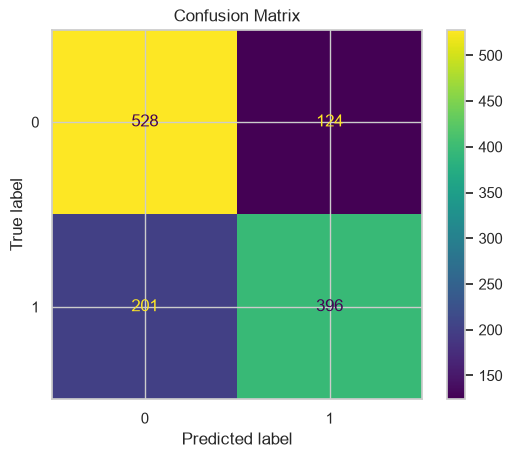

In [54]:
# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.title('Confusion Matrix')
plt.show()

### *6.6 Model Calibration*

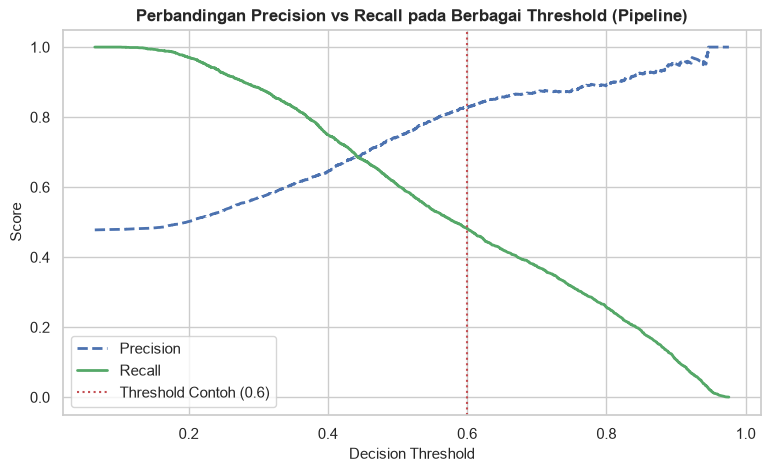

In [55]:
# Dapatkan probabilitas out-of-fold dari cross validation
y_proba_cv = cross_val_predict(best_model, x_train, y_train, cv=skfold, method='predict_proba')[:, 1]

# Hitung precision, recall, dan threshold
precisions, recalls, thresholds = precision_recall_curve(y_train, y_proba_cv)

# Plot grafik
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.xlabel("Decision Threshold", fontsize=11)
plt.ylabel("Score", fontsize=11)
plt.title("Perbandingan Precision vs Recall pada Berbagai Threshold (" + best_model.__class__.__name__ + ")", fontsize=12, fontweight='bold')
plt.axvline(x=0.6, color='r', linestyle=':', label='Threshold Contoh (0.6)')
plt.legend()
plt.grid(True)
plt.show()

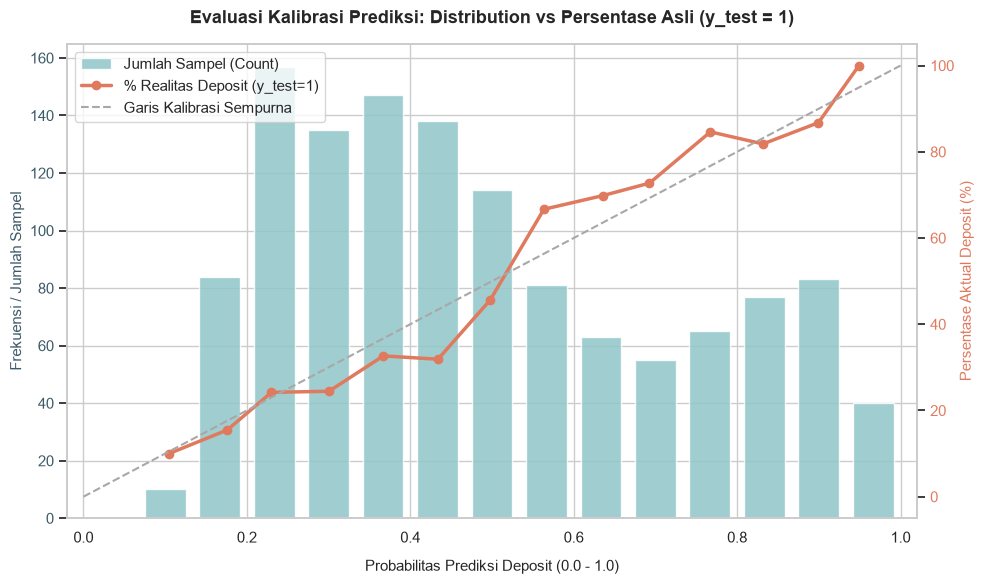

In [56]:
def plot_calibration_with_distribution(model, X_test, y_test, n_bins=15):
    # 1. Dapatkan probabilitas kelas positif (y_test = 1)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)
        y_prob = (y_prob - y_prob.min()) / (y_prob.max() - y_prob.min())

    # 2. Hitung titik kurva kalibrasi (probabilitas aktual vs nilai prediksi rata-rata)
    prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=n_bins, strategy='uniform')
    
    # 3. Setup Figure dan Axis Utama (Sumbu Y Kiri: Frekuensi / Jumlah Sampel)
    sns.set_theme(style="whitegrid")
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Bar chart histogram distribusi probabilitas prediksi
    counts, bin_edges = np.histogram(y_prob, bins=n_bins, range=(0, 1))
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_width = (bin_edges[1] - bin_edges[0]) * 0.75  # Memberi sedikit gap antar bar

    ax1.bar(
        bin_centers, 
        counts, 
        width=bin_width, 
        color='#90C5C7', 
        alpha=0.85, 
        label='Jumlah Sampel (Count)'
    )
    ax1.set_xlabel('Probabilitas Prediksi Deposit (0.0 - 1.0)', fontsize=11, labelpad=10)
    ax1.set_ylabel('Frekuensi / Jumlah Sampel', color='#3C5A67', fontsize=11)
    ax1.tick_params(axis='y', labelcolor='#3C5A67')
    ax1.set_xlim(-0.02, 1.02)

    # 4. Sumbu Y Kanan (Persentase Aktual Deposit dalam %)
    ax2 = ax1.twinx()
    
    # Line chart % realitas deposit (dalam bentuk persentase 0-100%)
    ax2.plot(
        prob_pred, 
        prob_true * 100, 
        marker='o', 
        linewidth=2.5, 
        color='#E07A5F', 
        label='% Realitas Deposit (y_test=1)'
    )
    
    # Garis diagonal kalibrasi sempurna (0% ke 100%)
    ax2.plot(
        [0, 1], 
        [0, 100], 
        linestyle='--', 
        color='#A8A8A8', 
        label='Garis Kalibrasi Sempurna'
    )
    
    ax2.set_ylabel('Persentase Aktual Deposit (%)', color='#E07A5F', fontsize=11)
    ax2.tick_params(axis='y', labelcolor='#E07A5F')
    ax2.set_ylim(-5, 105)
    ax2.grid(False)  # Matikan grid sumbu kanan agar tidak menumpuk dengan grid sumbu kiri

    # 5. Pengaturan Judul dan Legend
    plt.title(
        'Evaluasi Kalibrasi Prediksi: Distribution vs Persentase Asli (y_test = 1)', 
        fontsize=13, 
        fontweight='bold', 
        pad=15
    )

    # Menggabungkan legend dari kedua axis (ax1 & ax2)
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True)

    plt.tight_layout()
    plt.show()

# ==========================================
# Cara Panggil Fungsi dengan best_model Anda:
# ==========================================
plot_calibration_with_distribution(
    model=best_model, 
    X_test=x_test, 
    y_test=y_test, 
    n_bins=15
)

### *6.7 Model Explanation and Interpretation*

#### *6.7.1 Feature Importance*

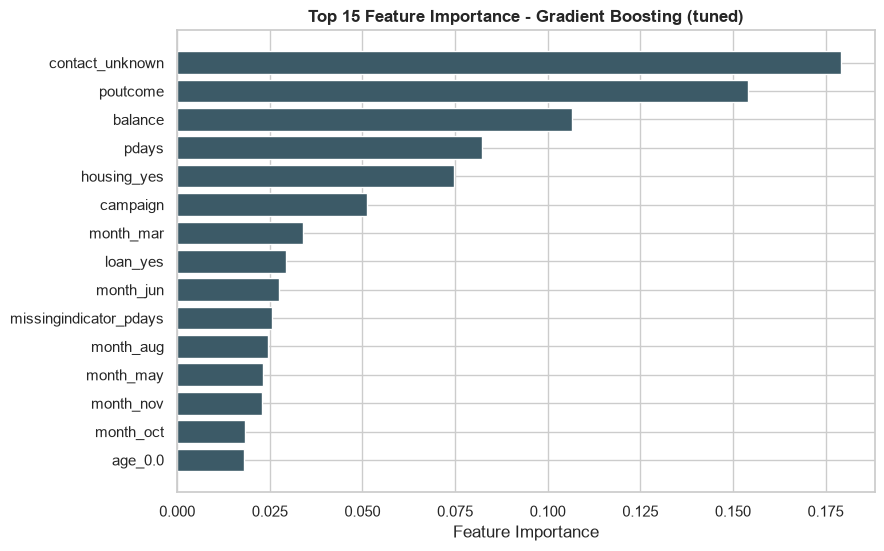

,feature,importance
0,contact_unknown,0.1793
1,poutcome,0.1541
2,balance,0.1066
3,pdays,0.0824
4,housing_yes,0.0748
5,campaign,0.0511
6,month_mar,0.0340
7,loan_yes,0.0293
8,month_jun,0.0276
9,missingindicator_pdays,0.0255


In [57]:
# Nama fitur setelah preprocessing
feature_names = best_model.named_steps['feature_preprocessing'].get_feature_names_out()

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': best_model.named_steps['model'].feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

# Plot Top 15 Feature Importance
plt.figure(figsize=(9, 6))
top_features = feature_importance.head(15).iloc[::-1]
plt.barh(top_features['feature'], top_features['importance'], color='#3C5A67')
plt.xlabel('Feature Importance')
plt.title('Top 15 Feature Importance - Gradient Boosting (tuned)', fontweight='bold')
plt.show()

feature_importance.head(15).round(4)

**Insight:**
- Tiga fitur paling berpengaruh adalah `contact_unknown`, `poutcome`, dan `balance`. Ketiganya menyumbang sekitar 42% dari total importance.
- Fitur berikutnya `pdays`, `housing_yes`, dan `campaign`, disusul bulan kontak (`month_mar`, `month_jun`) dan `loan_yes`.
- Fitur `job` dan `age` memiliki pengaruh yang kecil. Model lebih banyak bergantung pada **riwayat interaksi kampanye** dan **kondisi keuangan** nasabah dibandingkan profil demografi nasabahnya.

#### *6.7.2 SHAP Value Identification*

SHAP (SHapley Additive exPlanations) menjelaskan **arah dan besar pengaruh** tiap fitur terhadap prediksi setiap nasabah.
- Nilai SHAP **positif** mendorong prediksi ke arah *deposit = yes*.
- Nilai SHAP **negatif** mendorong prediksi ke arah *deposit = no*.
- Warna titik menunjukkan nilai fiturnya: **merah** = nilai tinggi, **biru** = nilai rendah.

Karena `age` di-binning menjadi 5 kelompok (one-hot), kolom `age_0.0` sampai `age_4.0` mewakili kelompok usia. Batas tiap kelompok ditampilkan di bawah.

In [58]:
# Batas kelompok usia hasil KBinsDiscretizer (quantile)
age_kbins = best_model.named_steps['feature_preprocessing'].named_transformers_['binning'].named_steps['feature_binning'].bin_edges_[0]
pd.DataFrame({
    'kolom': [f'age_{i}.0' for i in range(len(age_kbins) - 1)],
    'rentang_usia': [f'{age_kbins[i]:.0f} - {age_kbins[i + 1]:.0f}' for i in range(len(age_kbins) - 1)]
})

,kolom,rentang_usia
0,age_0.0,18 - 31
1,age_1.0,31 - 36
2,age_2.0,36 - 42
3,age_3.0,42 - 52
4,age_4.0,52 - 95


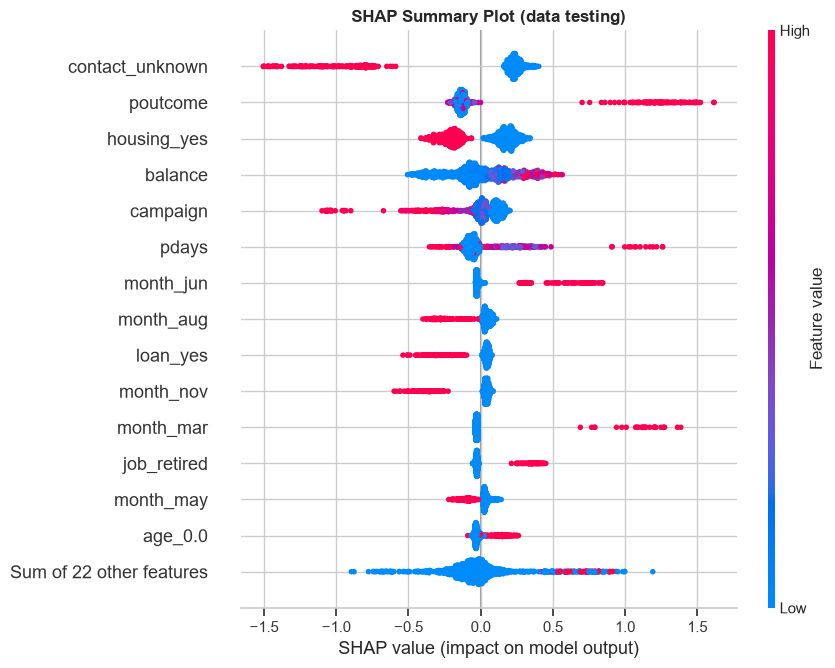

In [59]:
explainer = shap.TreeExplainer(best_model.named_steps['model'])
shap_values = explainer(x_test_pre)

# SHAP Summary Plot (beeswarm)
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('SHAP Summary Plot (data testing)', fontweight='bold')
plt.show()

Probabilitas deposit nasabah ini: 0.972


,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome
793,69,retired,426,no,no,telephone,mar,1,90,success


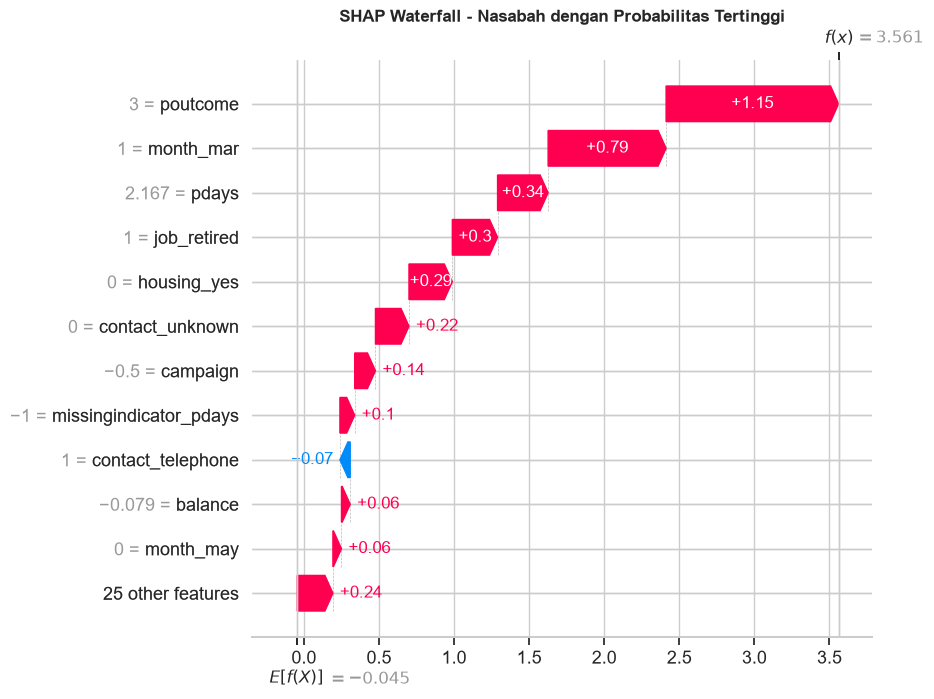

In [60]:
# Contoh penjelasan satu nasabah: nasabah dengan probabilitas deposit tertinggi di data testing
y_test_proba = best_model.predict_proba(x_test)[:, 1]
idx_top = int(np.argmax(y_test_proba))

print(f'Probabilitas deposit nasabah ini: {y_test_proba[idx_top]:.3f}')
display(x_test.iloc[[idx_top]])

shap.plots.waterfall(shap_values[idx_top], max_display=12, show=False)
plt.title('SHAP Waterfall - Nasabah dengan Probabilitas Tertinggi', fontweight='bold')
plt.show()

**Insight:**
- fitur `contact_unknown` adalah faktor penurun paling berpengaruh. Nasabah yang jenis kontaknya tidak tercatat **cenderung tidak** membuka deposit.
- `poutcome` tinggi (nilai 3 = `success`) mendorong prediksi ke *yes* dengan pengaruh yang sangat kuat. Nasabah yang berstatus sukses pada kampanye sebelumnya adalah prospek terbaik.
- `housing_yes` dan `loan_yes` menurunkan peluang deposit. Nasabah yang punya cicilan rumah atau pinjaman punya lebih sedikit dana menganggur.
- `balance` yang tinggi menaikkan peluang nasabah membuka deposit, sedangkan `campaign` yang tinggi (terlalu sering ditelepon) berpengaruh menurunkan peluang nasabah membuka deposit.
- `pdays` yang tinggi (nasabah pernah dihubungi di kampanye sebelumnya) sebagian besar mendorong menjadi *yes*, walaupun polanya tidak seragam.
- Bulan **Maret dan Juni** menaikkan peluang deposit, sedangkan **Agustus, November, dan Mei** menurunkan peluangnya.
- Nasabah pensiunan (`job_retired`) dan kelompok usia termuda (`age_0.0` atau 18–31 tahun) sedikit menaikkan peluang deposit.
- Pada contoh waterfall, nasabah dengan probabilitas tertinggi (0,972) adalah pensiunan berusia 69 tahun. Prediksinya didorong terutama oleh `poutcome = success`, kontak di bulan Maret, `pdays`, dan status pensiunan.

#### *6.7.3 Counterfactual Analysis*

Counterfactual menjawab pertanyaan: *"apa yang perlu berubah supaya prediksi model berubah?"*

Diambil satu nasabah yang diprediksi **no** (tidak) deposit dengan probabilitas paling dekat ke threshold 0,5, lalu dicoba mengubah fitur yang bisa dikendalikan bank yaitu bulan kontak (`month`) dan jenis kontak (`contact`), satu per satu. Fitur seperti `age`, `job`, atau `balance` tidak diubah karena bukan hal yang bisa dikendalikan bank.

In [61]:
# Nasabah yang diprediksi "no" dengan probabilitas paling dekat ke threshold 0,5
candidates = np.where(y_test_proba < 0.5)[0]
idx_cf = int(candidates[np.argmax(y_test_proba[candidates])])
customer = x_test.iloc[[idx_cf]]

print(f'Probabilitas awal: {y_test_proba[idx_cf]:.3f} (prediksi: no)')
display(customer)

counterfactualResult = []
for feature in ['month', 'contact']:
    for value in sorted(x_train[feature].unique()):
        if value == customer[feature].iloc[0]:
            continue
        what_if = customer.copy()
        what_if[feature] = value
        proba = best_model.predict_proba(what_if)[0, 1]
        counterfactualResult.append({
            'feature': feature,
            'nilai_awal': customer[feature].iloc[0],
            'nilai_baru': value,
            'probabilitas_baru': proba,
            'perubahan': proba - y_test_proba[idx_cf],
            'prediksi_baru': 'yes' if proba >= 0.5 else 'no'
        })

counterfactualDf = pd.DataFrame(counterfactualResult).sort_values('probabilitas_baru', ascending=False)
counterfactualDf.round(3)

Probabilitas awal: 0.499 (prediksi: no)


,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome
971,35,technician,3490,yes,no,cellular,aug,2,-1,unknown


,feature,nilai_awal,nilai_baru,probabilitas_baru,perubahan,prediksi_baru
6,month,aug,mar,0.821,0.323,yes
10,month,aug,sep,0.769,0.270,yes
5,month,aug,jun,0.764,0.265,yes
9,month,aug,oct,0.734,0.236,yes
1,month,aug,dec,0.727,0.229,yes
2,month,aug,feb,0.560,0.062,yes
0,month,aug,apr,0.547,0.049,yes
7,month,aug,may,0.541,0.042,yes
4,month,aug,jul,0.514,0.015,yes
11,contact,cellular,telephone,0.467,-0.031,no


In [62]:
# Efek rata-rata mengubah bulan kontak untuk semua nasabah di data testing yang diprediksi "no"
predicted_no = x_test[y_test_proba < 0.5]

monthEffect = []
for month in ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']:
    proba = best_model.predict_proba(predicted_no.assign(month=month))[:, 1]
    monthEffect.append({
        'month': month,
        'rata_rata_probabilitas': proba.mean(),
        'proporsi_jadi_yes': (proba >= 0.5).mean()
    })

print('Jumlah nasabah yang diprediksi no:', len(predicted_no))
pd.DataFrame(monthEffect).round(3)

Jumlah nasabah yang diprediksi no: 729


,month,rata_rata_probabilitas,proporsi_jadi_yes
0,jan,0.253,0.014
1,feb,0.351,0.099
2,mar,0.671,0.940
3,apr,0.375,0.160
4,may,0.351,0.128
5,jun,0.518,0.623
6,jul,0.352,0.081
7,aug,0.316,0.055
8,sep,0.517,0.597
9,oct,0.558,0.642


**Insight:**
- Untuk nasabah contoh (probabilitas awal sekitar 0,50 dengan prediksi **no**), mengganti bulan kontak dari Agustus menjadi **Maret** menaikkan probabilitas ke sekitar **0,82**. Mengganti bulannya menjadi **September, Juni, Oktober, atau Desember** juga mengubah prediksi menjadi *yes* (sekitar 0,73–0,77).
- Mengganti jenis kontak dari cellular menjadi **telephone** sedikit menurunkan probabilitas (0,47), dan menjadi **unknown** turun jauh (0,23). Jadi, kontak lewat seluler adalah pilihan terbaik.
- Secara rata-rata, kalau semua nasabah yang diprediksi **no** di data testing dihubungi di bulan **Maret**, sekitar 94% berubah prediksinya menjadi **yes**. Bulan Desember sekitar 66%, Oktober 64%, Juni 62%, dan September 60%, sedangkan bulan Januari dan November hampir tidak mengubah apa-apa.
- Artinya, model sangat bergantung pada **waktu kontak** dan **jenis kontak**. Keduanya adalah faktor yang bisa dikendalikan bank saat menyusun jadwal kampanye.

## **Section 7. Model Deployment**

### *7.1 Export Model (joblib/pickle)*

Model akhir dilatih ulang memakai seluruh data **seen** (`x`, `y`). Data unseen tetap tidak dipakai.

In [63]:
best_model.fit(x,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','job','balance',...,'campaign','pdays','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_nominal', ...), ('numerical', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is eq

In [64]:
# Save to pickle object
with open('model_gboost_v1.sav','wb') as file:
    pickle.dump(best_model, file)

In [65]:
with open('model_gboost_v1.sav', 'rb') as file:
    model = pickle.load(file)

### *7.2 Deployment Checklist*

In [66]:
# Library Version
# Cek Versi Library untuk requirements.txt
import matplotlib
import feature_engine

# (Opsional) Jika juga digunakan saat deployment / dashboard
# import imblearn
# import category_encoders
# import uvicorn
# import streamlit
# import plotly

packages = {
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
    "feature-engine": feature_engine.__version__,
    "xgboost": xgboost.__version__,
    "lightgbm": lightgbm.__version__,
    "shap": shap.__version__,
    "joblib": joblib.__version__,
    "optuna": optuna.__version__,
}
 
for pkg_name, version in packages.items():
    print(f"{pkg_name}=={version}")

pandas==3.0.5
numpy==2.5.3
matplotlib==3.11.1
seaborn==0.13.2
scikit-learn==1.9.1
feature-engine==1.9.4
xgboost==3.4.1
lightgbm==4.7.0
shap==0.54.1
joblib==1.6.0
optuna==5.0.0


In [67]:
with open("requirements.txt", "w") as f:
    for pkg_name, version in packages.items():
        f.write(f"{pkg_name}=={version}\n")

print("File requirements.txt berhasil dibuat!")

File requirements.txt berhasil dibuat!


## **Section 8. Model Implementation**

### *8.1 How to implement the model?*

In [68]:
# Data unseen (dipisah di Section 3.2) sebagai data nasabah baru
x_unseen = df_unseen.drop(columns='deposit')
y_unseen = df_unseen['deposit'].map({'no': 0, 'yes': 1})

# Membuat kolom id di urutan paling depan
testing_unseen = x_unseen.copy()
testing_unseen.insert(0, 'id', testing_unseen.index + 1)

# Menyimpan ke CSV
testing_unseen.to_csv('testing.csv', index=False)
testing_unseen.head()

,id,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome
0,1,39,technician,287,yes,no,cellular,jul,3,-1,unknown
1,2,42,technician,994,yes,no,cellular,may,5,-1,unknown
2,3,28,blue-collar,-46,yes,no,cellular,mar,1,89,failure
3,4,36,services,0,yes,no,cellular,may,6,-1,unknown
4,5,29,technician,510,yes,no,unknown,jun,15,-1,unknown


File testing.csv nantinya akan digunakan dalam simulasi model

### *8.2 What are the limitations of the model?*

Meskipun model ini efektif untuk meningkatkan efisiensi kampanye, terdapat beberapa batasan operasional dan teknis yang perlu diperhatikan:

- **Ambiguitas akibat Overlapping Data (Zona Abu-abu)**
    Karakteristik nasabah yang menolak dan menerima sering kali sangat mirip, menyebabkan penumpukan prediksi yang ragu-ragu di rentang probabilitas 0.4 – 0.6. Namun, prediksi dengan probabilitas di atas 0.6 terbukti sangat andal dengan tingkat presisi di atas 80%. Oleh karena itu, model ini sangat disarankan penggunaannya sebatas sebagai penentu urutan prioritas kontak (lead prioritization), bukan sebagai penentu mutlak klasifikasi (Pasti Deposit / Tidak).

- **Ketergantungan Kuat pada Riwayat Kampanye Masa Lalu**
    Model sangat mengandalkan fitur riwayat interaksi sebelumnya. Akibatnya, model mengalami cold-start problem (kurang presisi/percaya diri) saat harus menilai prospek yang benar-benar baru dan belum pernah dihubungi sama sekali.

- **Bias pada Segmen Komunikasi yang Tidak Jelas (contact = unknown)**
    Prospek yang sebenarnya berpotensi tinggi bisa mendapatkan skor probabilitas yang rendah secara drastis apabila saluran komunikasinya tidak tercatat dengan baik di sistem (unknown). Kualitas prediksi sangat bergantung pada kelengkapan pencatatan data ini.

- **Kekakuan pada Pola Musiman Historis (Historical Seasonality)**
    Model menangkap tren bulan-bulan tertentu sebagai "waktu emas" berdasarkan riwayat data lama. Jika tim marketing di masa depan mengubah jadwal strategi kampanye besar ke bulan lain, model bisa gagal mendeteksi lonjakan potensi karena terlalu kaku pada pola kalender masa lalu.

### *8.3 Business Calculation (Simulation using unseen data)*

In [69]:
# ==========================================
# 1. PERSIAPAN DATA EVALUASI (MENGGUNAKAN DATA UNSEEN)
# ==========================================
df_eval = x_unseen.copy()
df_eval['actual_deposit'] = y_unseen.values

# Pisahkan fitur dari id dan target
X_eval = df_eval.drop(columns=['id', 'actual_deposit'], errors='ignore')

# ==========================================
# 2. HITUNG PREDIKSI PROBABILITAS MODEL
# ==========================================
df_eval['deposit_probability'] = best_model.predict_proba(X_eval)[:, 1]

# Urutkan berdasarkan probabilitas tertinggi ke terendah (Top-N Ranking)
df_eval = df_eval.sort_values(by='deposit_probability', ascending=False).reset_index(drop=True)

# ==========================================
# 3. PARAMETER BIAYA, KEUNTUNGAN & KUOTA PANGGIL
# ==========================================
COST_PER_CALL = 15000       # Biaya operasional telemarketing per 1 panggilan (Rp)
PROFIT_PER_DEPOSIT = 250000 # Keuntungan bersih bank per sukses deposit (Rp)

TOTAL_QUOTA_CALLS = 500     # Batas maksimal panggilan sesuai skenario

# ==========================================
# 4. SKENARIO 1: TANPA MODEL (MENELEPON 500 SECARA ACAK EMPIRIS)
# ==========================================
total_customers = len(df_eval)
total_actual_success = df_eval['actual_deposit'].sum()

# Ambil 500 sampel secara acak murni dari total data uji
df_random_500 = df_eval.sample(n=TOTAL_QUOTA_CALLS, random_state=RANDOM_STATE)
success_baseline_random = df_random_500['actual_deposit'].sum()

cost_baseline = TOTAL_QUOTA_CALLS * COST_PER_CALL
revenue_baseline = success_baseline_random * PROFIT_PER_DEPOSIT
net_profit_baseline = revenue_baseline - cost_baseline

# ==========================================
# 5. SKENARIO 2: MENGGUNAKAN MODEL (TOP 500 NASABAH TERATAS)
# ==========================================
# Ambil tepat 500 nasabah dengan probabilitas tertinggi dari model
df_top_500 = df_eval.head(TOTAL_QUOTA_CALLS)
success_captured_model = df_top_500['actual_deposit'].sum()

revenue_model = success_captured_model * PROFIT_PER_DEPOSIT
net_profit_model = revenue_model - cost_baseline

# ==========================================
# 6. CETAK LAPORAN SIMULASI BISNIS
# ==========================================
print("=" * 65)
print(f"   SIMULASI DAMPAK BISNIS (KUOTA TERBATAS: {TOTAL_QUOTA_CALLS} DARI {total_customers} NASABAH)")
print("=" * 65)
print(f"Total Prospek Tersedia     : {total_customers:,} nasabah")
print(f"Total Target Sukses Aktual : {total_actual_success:,} nasabah di dalam data unseen\n")

print(f"--- SKENARIO 1: Tanpa Model (Menelepon 500 Acak Empiris) ---")
print(f"Total Panggilan Dialihkan : {TOTAL_QUOTA_CALLS}")
print(f"Nasabah Sukses Terjaring  : {success_baseline_random:,} nasabah (hasil sampel acak)")
print(f"Total Biaya Telemarketing : Rp {cost_baseline:,.0f}")
print(f"Total Keuntungan Bersih   : Rp {net_profit_baseline:,.0f}\n")

print(f"--- SKENARIO 2: Dengan Model (Top {TOTAL_QUOTA_CALLS} Nasabah Teratas) ---")
print(f"Total Panggilan Dialihkan : {TOTAL_QUOTA_CALLS} (Fokus pada Hot Leads)")
print(f"Nasabah Sukses Terjaring  : {success_captured_model:,} nasabah (hasil seleksi model)")
print(f"Total Biaya Telemarketing : Rp {cost_baseline:,.0f}")
print(f"Total Keuntungan Bersih   : Rp {net_profit_model:,.0f}\n")

print("=" * 65)
profit_diff = net_profit_model - net_profit_baseline
success_diff = success_captured_model - success_baseline_random
print(f"PENINGKATAN NASABAH SUKSES   : +{success_diff} orang")
print(f"PENINGKATAN NET PROFIT       : Rp {profit_diff:,.0f}")
print("=" * 65)

   SIMULASI DAMPAK BISNIS (KUOTA TERBATAS: 500 DARI 1561 NASABAH)
Total Prospek Tersedia     : 1,561 nasabah
Total Target Sukses Aktual : 746 nasabah di dalam data unseen

--- SKENARIO 1: Tanpa Model (Menelepon 500 Acak Empiris) ---
Total Panggilan Dialihkan : 500
Nasabah Sukses Terjaring  : 227 nasabah (hasil sampel acak)
Total Biaya Telemarketing : Rp 7,500,000
Total Keuntungan Bersih   : Rp 49,250,000

--- SKENARIO 2: Dengan Model (Top 500 Nasabah Teratas) ---
Total Panggilan Dialihkan : 500 (Fokus pada Hot Leads)
Nasabah Sukses Terjaring  : 409 nasabah (hasil seleksi model)
Total Biaya Telemarketing : Rp 7,500,000
Total Keuntungan Bersih   : Rp 94,750,000

PENINGKATAN NASABAH SUKSES   : +182 orang
PENINGKATAN NET PROFIT       : Rp 45,500,000


**Insight:**
- Simulasi memakai **1.561 nasabah unseen** yang tidak pernah dipakai untuk EDA, training, tuning, maupun training model akhir. Dari jumlah itu, 746 nasabah benar-benar membuka deposit.
- Dengan kuota 500 panggilan, menelepon secara **acak** menjaring **227 nasabah** deposit (tingkat keberhasilan 45,4%), sedangkan menelepon **500 nasabah teratas versi model** menjaring **409 nasabah** (81,8%).
- Model menambah **+180 nasabah deposit** dan **+Rp 45.500.000 net profit** dengan biaya telemarketing yang sama (Rp 7.500.000).
- Di data unseen, nasabah dengan probabilitas di atas 0,6 memiliki presisi **86%** (413 nasabah), sesuai dengan *success criteria* di Section 1.6.

## **Section 9. Conclusion and Recommendation**

### *9.1 Conclusion*
1. Conclusion (Model)
    - Performa & Pemilihan Algoritma: Model Gradient Boosting Classifier terpilih sebagai model terbaik setelah melalui rangkaian tuning hyperparameter menggunakan Optuna. Model ini terbukti paling stabil dan akurat dalam menangkap pola non-linier dibandingkan model baseline maupun feature selection statistik univariat (SelectFpr) yang tidak memberikan peningkatan performa.

    - Optimalisasi Rekayasa Fitur (Feature Engineering): Eksperimen membuktikan bahwa model berbasis tree-based bekerja paling optimal menggunakan fitur asli yang diproses melalui One-Hot Encoding (~35–38 fitur), tanpa memerlukan penambahan fitur interaksi biner buatan manusia yang justru memicu over-constraining.

    - Kalibrasi & Distribusi Probabilitas: Evaluasi kalibrasi menunjukkan adanya fenomena overlapping data yang cukup tinggi pada rentang probabilitas abu-abu (0.4 – 0.6). Namun, model memiliki tingkat keandalan yang sangat tinggi dengan presisi di atas 80% untuk skor probabilitas di atas 0.6.

2. Conclusion (Business)
    - Penyelesaian Batasan Operasional: Dengan adanya keterbatasan sumber daya di mana tim telemarketing hanya mampu melakukan 500 panggilan dari total 1.561 prospek nasabah, model ini berhasil bertindak sebagai alat penyaring yang sangat efektif (Top-N Lead Prioritization).

    - Dampak Finansial & Efisiensi: Simulasi berbasis data unseen membuktikan bahwa alih-alih menelepon nasabah secara acak, penerapan model ini mampu memangkas pemborosan waktu dan biaya operasional secara drastis sekaligus menjaring jumlah nasabah sukses deposit yang jauh lebih tinggi.

    - Pencapaian Tujuan Utama: Proyek ini sukses menjawab Goals awal, yaitu menghadirkan solusi berbasis Machine Learning yang tidak hanya unggul secara metrik statistik, tetapi juga memberikan keunggulan kompetitif dan peningkatan Net Profit yang nyata bagi operasional perbankan.

### *9.2 Recommendation*
1. Recommendation (Model)
    - Penambahan Fitur Berdampak Tinggi (High-Impact Feature Engineering):
    Mengingat model saat ini hanya bergantung pada demografi dasar dan riwayat kampanye, ke depannya perlu diintegrasikan fitur perilaku digital nasabah (seperti frekuensi login aplikasi mobile banking, kepemilikan produk lain seperti kartu kredit atau KPR aktif, serta rata-rata rasio penggunaan saldo terhadap batas minimum). Fitur finansial mendalam ini biasanya memiliki information gain yang jauh lebih kuat untuk memprediksi likuiditas dan minat deposito.
    
    - Pembaruan Model Berkala (Model Retraining & Drift Monitoring):
    Menetapkan jadwal rutin (monthly/quarterly retraining) untuk memperbarui model agar dapat menangkap pergeseran perilaku nasabah (data drift) dan perubahan tren suku bunga pasar.
2. Recommendation (Business)
    - Adopsi Penuh Strategi Tiered Lead Prioritization:
    Mengintegrasikan daftar hasil batch scoring model (kategori Tier 1 dan Tier 2) langsung ke dalam sistem CRM operasional tim telemarketing. Agen diwajibkan untuk memprioritaskan kontak kepada nasabah dengan skor probabilitas tertinggi di pagi hari untuk memaksimalkan tingkat konversi.
    
    - Peningkatan Kualitas Pencatatan Data CRM (Data Hygiene):
    Mengatasi masalah batasan model terkait nilai unknown pada kanal komunikasi (contact) atau pekerjaan (job). Manajemen perlu memperketat SOP bagi staf operasional atau kanal digital agar pengisian data profil nasabah di database diisi secara lengkap (mandatory fields), sehingga model dapat memberikan penilaian probabilitas yang lebih adil dan akurat bagi setiap prospek.